# GKD Stage B — cross-init 7×7 factorial — `20260809_breadth4_160m`

End-to-end analysis of the **completed** animal-breadth Stage B campaign: the
cross-init teacher-init × student-init factorial at the **frozen** on-policy GKD
recipe, plus matched base-teacher controls. Four animals, seven PolyPythia-160M
inits, one shared winner recipe. This is the four-animal successor to
`notebooks/gkd_cross_init_factorial.ipynb` (the earlier two-animal
`20260727_slbreadth_160m` run).

Campaign SSOT: `subliminal_learning.campaign.breadth_plan` and
`subliminal_learning.campaign.pairs`. Behaviour tree:
`gkd_students/{RUN_SET_ID}`. Teachers:
`sdf_teachers/{TEACHER_RUN_SET_ID}`. Paths resolve from
`configs/paths/paths_local.yaml` via `analysis.setup.bootstrap` — **never
hardcode SSD roots**. This notebook is **read-only** on cached summaries /
manifests / probe JSONL. It does not train, does not write under
`output_root`, and does not load `rollouts_sample.jsonl`.

**Run from the repo root:**
```bash
uv sync
uv run jupyter lab
```
Open `notebooks/gkd_breadth4_cross_init_factorial.ipynb` and run all cells
top-to-bottom.

### Reading guide — aggregation rules

- `subliminal_delta` already averages treatments over **teacher ftseed** within
  `(animal, model, gkd_tag, set, teacher_cross_init, teacher_base_label)` and
  joins the matched control on `(animal, model, gkd_tag, set)`. **Never
  re-average those rows over ftseed.**
- `subliminal_delta_ci` pairs **gseeds** (after averaging tfs) and uses a
  t-interval over `n_pairs=3` — low power. Use it for per-config intervals;
  use a **pairing-cluster bootstrap** (resample pairing means; percentile
  interval; fixed seed) for corner / group / Cloud-test intervals.
- Do **not** treat `ci_lower` / `ci_upper` on preference rows as paired-seed
  CIs, and do **not** treat `delta_vs_base` as the Cloud effect (that column
  is versus the **untuned** base, not the GKD control).
- **Never pool headline (3 tfs × 3 gseeds) with extension (1 tfs × 3 gseeds)
  in a single CI.** Report the two tiers separately.
- **Never pool raw `p_target` across animals.** Control floors differ; Δ is
  the comparable quantity, and even Δ is heterogeneous (see §7).
- Same `gkd_tag` appears on same-init and cross-init leaves. Always keep
  `teacher_cross_init` / `teacher_base_label` when joining.
- Loader `teacher_base_label` spells seed-0 as **`full-seed0`**; `pairs.py`
  and `short_model()` use **`original`**; the disk dir is `pythia-160m`.
  Normalize before joining. Unmapped models raise.
- Pairings are **directed**. Do not treat A→B as B→A.
- Dedup probe rows by `(run_dir, step)` before any trajectory aggregate
  (resume-append duplicates). Filter `~diverged` before
  `end_of_run_probes` / `peak_probes`. Sensitivity drops **all** diverged
  leaves, not one.
- Probe metrics are training-time, not eval-grade. Preference / FC /
  capability summaries are the eval-grade tables.
- Two distinct floors: (a) untuned base (`base_p_target`,
  `base_control.json`); (b) GKD-from-unfinetuned-teacher under
  `controls/base_teacher/`. Subliminal Δ uses (b).
- No formal Stage-B pre-registration was filed. Every pairing ranking here
  is **post-hoc**.
- H1/H2 adjudication is **out of scope**. The 2×2 is a replication surface
  only. If mentioned: **H1** = pairings sharing *batch composition*
  (`weight_cyclic`: different init ∩ shared stream) transfer better than
  those sharing *weight init* (`data_cyclic`: shared init ∩ different
  stream); **H2** = neither, because the trait rides init-independent
  vocabulary geometry.

### What this notebook covers

| § | Topic |
|---|---|
| 0 | Provenance (pin, freeze, init-equality premise, pauses, queue) |
| 1 | Frozen tag + inventory (coverage asserts, triad, Stage A overlap) |
| 2 | 7×7 teacher × student leaf-count coverage |
| 3 | Control floor by student init × animal |
| 4 | Headline Δ heatmaps (2×2 animals) + optional raw `p_target` |
| 5 | 2×2 corner factorial (descriptive; pairing-cluster CIs) |
| 6 | **Primary — Cloud shared-init test** |
| 7 | Animal heterogeneity of Δ |
| 8 | Teacher-strength confound |
| 9 | Student-base confound (`delta_vs_same_init_anchor`) |
| 10 | Family breakdown (data vs weight) |
| 11 | Direction asymmetry (A→B vs B→A) |
| 12 | Seeds and power (headline vs extension; never pooled) |
| 13 | Prompt-set ladder including storytelling |
| 14 | Specificity (FC + 4×4 off-target) and capability (PPL + lm-eval) |
| 15 | Probe trajectories by corner (dedup + divergence QC) |
| 16 | Optimization / loss-matching |
| 17 | Behavioural leakage telemetry |
| 18 | Concordance with `20260727_slbreadth_160m` |
| 19 | Takeaways (from frames) + claims + knobs |

### 2×2 design (init × stream)

`init_seed` is 0 unless `weight-seed{N}`; `stream_seed` is 0 unless
`data-seed{N}`; `original` is seed-0 on both. Corners are derived from those
seeds, **not** from `CORNER_GROUPS`. Expected pairing counts are computed
in the setup cell from `stage_b_pairs()` (asserted against
`CORNER_COUNTS_EXPECTED`).

|  | shared stream | different stream |
|---|---|---|
| shared init | SI∩SS (same-init diagonal) | SI∩DS (`data_cyclic` + seed-0 data) |
| different init | DI∩SS (`weight_cyclic` + seed-0 weight) | DI∩DS (`family_swap`) |

PolyPythias caveat: a published seed jointly varies weight init **and**
batch composition. “Batch composition” is the correct term, not “data
order”.

### Explicit exclusions

- H1/H2 factor call / majority-vote verdict (campaign plan excludes
  re-litigating this pair).
- β=0 / forward-KL, Stage C (λ / vocab_mask / full-FT teacher), CKA / EAS /
  steering predictors, random-teacher / shuffle / ICL negatives.
- PolyPythia seeds 1–9 as extra inits, model-size sweeps, promoting
  extension arms to 3 tfs.
- `docs/CAMPAIGN_RESULTS_SLBREADTH.md` (does not exist). Prior-run numbers
  come from `docs/RUN_INVENTORY.md` or from the slbreadth tree in §18.
- Imputing `benchmarks` on extension dirs (absent by design).
- Loading `rollouts_sample.jsonl` (use `rollouts_summary.json`).
- Writing figures or any file under `output_root`.

### Metric cheat-sheet

| ID | Answers | Values | How scored | Notes |
|---|---|---|---|---|
| `subliminal_delta` | Did GKD from this teacher raise target-animal preference above a matched **base-teacher** control? | Difference of two probabilities | `p_target_treatment − p_target_control` on the primary `test` / `prob` set: mean over prompts of exact last-token p(leading-space animal token) | Cloud SL effect. Treatments averaged over ftseed; control matched on (animal, student init, gkd_tag, set). |
| control floor | What preference does the same student show after GKD from an **unfinetuned** teacher at the frozen recipe? | [0, 1] | Control `p_target` on the same set | Not the untuned-base `base_p_target`. |
| same-init vs cross-init | Does transfer require a shared teacher/student initialization (Cloud)? | Δ means + `cross_positive_frac` + sign test | Same-init: `student_base == teacher_base`. Cross: otherwise | Headline scientific question (§6). |
| `delta_vs_same_init_anchor` | How much extra / missing Δ does a pairing have vs **that student’s own same-init** cell? | Difference of two deltas | `Δ(pair) − Δ(same-init, same student, same animal, same set)` | **Notebook-local** analysis choice (checkpoint-ladder `y` precedent). Not a repo-standard metric. |
| FC `target_share` | Is the preference specific among 10 roster animals? | [0, 1] | Softmax over the 10-animal roster | All four campaign animals are in the roster. |
| `perplexity_ratio` | Did GKD degrade LM capability vs the student’s own base? | (0, ∞); 1 = unchanged | Pile PPL / base PPL | Finite-mask before aggregates. |
| lm-eval acc | Is the student still usable? | [0, 1] | 0-shot `arc_easy` / `lambada_openai` / `sciq` | Present on headline treat + all frozen controls; **absent on extension by design**. |
| storytelling Δ | Does the Cloud-parity OOD set agree with `test`? | sample hit rate − control | `scoring=sample`, `n_prompts` smaller than the prob sets | New this campaign; rank fields are null by design. |
| β / λ | What distillation objective? | β=1.0 reverse-KL (mode-seeking); λ=1.0 fully on-policy | Frozen recipe | Generalized JSD mix. |


## Setup


In [1]:
from __future__ import annotations

import json
import math
import re
import sys
import time
from collections import Counter
from collections.abc import Mapping, Sequence
from datetime import datetime
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from scipy.stats import friedmanchisquare, kruskal, spearmanr

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import stats as astats
from subliminal_learning.analysis.frames import print_scope, scope_str, short_model
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.campaign.breadth_plan import (
    ANIMALS,
    BETAS,
    B_CONTROL_CELLS,
    B_GSEEDS,
    B_TFS_EXTENSION,
    B_TFS_HEADLINE,
    B_TREAT_CELLS,
    CAMPAIGN_DONE_FILE,
    CAMPAIGN_STATE_FILE,
    EVAL_PROMPT_SETS,
    FREEZE_REPORT,
    INIT_EQUALITY_REPORT,
    LMBDA,
    RUN_SET_ID,
    TEACHER_PARAM_TAG_LORA,
    TEACHER_RUN_SET_ID,
)
from subliminal_learning.campaign.pairs import (
    CORNER_GROUPS,
    GROUP_DATA_CYCLIC,
    GROUP_FAMILY_SWAP,
    GROUP_SAME,
    GROUP_SEED0_DATA,
    GROUP_SEED0_WEIGHT,
    GROUP_WEIGHT_CYCLIC,
    stage_b_pairs,
    stage_b_student_models,
)
from subliminal_learning.campaign.selection import end_of_run_probes, peak_probes
from subliminal_learning.evaluation.gkd_results_io import (
    DIVERGENCE_PPL_FACTOR,
    load_gkd_capability_results,
    load_gkd_forced_choice_results,
    load_gkd_preference_results,
    load_gkd_probe_trajectories,
    load_gkd_train_manifests,
    load_gkd_training_logs,
    parse_gkd_tag,
    parse_teacher_tag,
    probe_subliminal_delta,
    subliminal_delta,
    subliminal_delta_ci,
    subliminal_delta_sign_test,
)
from subliminal_learning.evaluation.preference_scoring import sign_test
from subliminal_learning.evaluation.sdf_results_io import load_sdf_preference_results

ROOT, OUTPUT_ROOT = bootstrap()
sys.path.insert(0, str(ROOT / "src"))
set_plot_style()

_paths = __import__("yaml").safe_load(
    (ROOT / "configs" / "paths" / "paths_local.yaml").read_text()
)
QUEUE_ROOT = Path(_paths["queue_root"])

SUBDIR = f"gkd_students/{RUN_SET_ID}"
TREE = OUTPUT_ROOT / SUBDIR
TEACHER_SUBDIR = f"sdf_teachers/{TEACHER_RUN_SET_ID}"
TEACHER_TREE = OUTPUT_ROOT / TEACHER_SUBDIR
SLBREADTH_SUBDIR = "gkd_students/20260727_slbreadth_160m"
SLBREADTH_TREE = OUTPUT_ROOT / SLBREADTH_SUBDIR

PROMPT_SETS: tuple[str, ...] = EVAL_PROMPT_SETS
PRIMARY_SET = "test"
DEEP_ANIMAL = ANIMALS[0]
BOOTSTRAP_SEED = astats.BOOTSTRAP_SEED
N_BOOT = astats.N_BOOT

assert TREE.is_dir(), f"missing run tree: {TREE}"
assert not any(
    part.startswith("/mnt/") for part in (str(SUBDIR),)
), "subdir must be relative"

print("output_root :", OUTPUT_ROOT)
print("subdir      :", SUBDIR)
print("tree        :", TREE)
print("teacher     :", TEACHER_TREE)
print("queue_root  :", QUEUE_ROOT)
print("run_set_id  :", RUN_SET_ID)
print("animals     :", ANIMALS)
print("betas       :", BETAS, "lmbda:", LMBDA)
print("eval sets   :", PROMPT_SETS)
print("deep animal :", DEEP_ANIMAL)
print("bootstrap   :", BOOTSTRAP_SEED, "n_boot", N_BOOT)


output_root : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning
subdir      : gkd_students/20260809_breadth4_160m
tree        : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260809_breadth4_160m
teacher     : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/sdf_teachers/20260809_breadth4-teachers_160m
queue_root  : /mnt/ssd-3/soar-subliminal/vishesh/run_logs/queue
run_set_id  : 20260809_breadth4_160m
animals     : ('cat', 'dog', 'bear', 'eagle')
betas       : (1.0,) lmbda: 1.0
eval sets   : ('test', 'favorite', 'dislike', 'validation', 'consensus', 'register', 'storytelling')
deep animal : cat
bootstrap   : 20260805 n_boot 10000


### Helper functions (pairing labels, bootstrap, leaf readers)


In [2]:
MODEL_TO_LABEL: dict[str, str] = {
    "pythia-160m": "original",
    "pythia-160m-data-seed1": "data-seed1",
    "pythia-160m-data-seed2": "data-seed2",
    "pythia-160m-data-seed3": "data-seed3",
    "pythia-160m-weight-seed1": "weight-seed1",
    "pythia-160m-weight-seed2": "weight-seed2",
    "pythia-160m-weight-seed3": "weight-seed3",
}
LABEL_TO_MODEL: dict[str, str] = {v: k for k, v in MODEL_TO_LABEL.items()}
BASE_ORDER: list[str] = list(stage_b_student_models())
CORNER_SHARED_INIT_SHARED_STREAM = "shared_init_shared_stream"
CORNER_DIFF_INIT_SHARED_STREAM = "diff_init_shared_stream"
CORNER_SHARED_INIT_DIFF_STREAM = "shared_init_diff_stream"
CORNER_DIFF_INIT_DIFF_STREAM = "diff_init_diff_stream"
CORNER_ORDER: list[str] = [
    CORNER_SHARED_INIT_SHARED_STREAM,
    CORNER_DIFF_INIT_SHARED_STREAM,
    CORNER_SHARED_INIT_DIFF_STREAM,
    CORNER_DIFF_INIT_DIFF_STREAM,
]
CORNER_SHORT: dict[str, str] = {
    CORNER_SHARED_INIT_SHARED_STREAM: "SI∩SS (same init)",
    CORNER_DIFF_INIT_SHARED_STREAM: "DI∩SS (shared stream)",
    CORNER_SHARED_INIT_DIFF_STREAM: "SI∩DS (shared init)",
    CORNER_DIFF_INIT_DIFF_STREAM: "DI∩DS (family swap)",
}
CORNER_COUNTS_EXPECTED: dict[str, int] = {
    CORNER_SHARED_INIT_SHARED_STREAM: 7,
    CORNER_DIFF_INIT_SHARED_STREAM: 9,
    CORNER_SHARED_INIT_DIFF_STREAM: 9,
    CORNER_DIFF_INIT_DIFF_STREAM: 6,
}
PAIR_LOOKUP = {(p.student, p.teacher): p for p in stage_b_pairs()}
HEADLINE_PAIRS = tuple(p for p in stage_b_pairs() if p.headline)
ANIMAL_COLORS = {
    "cat": "C0",
    "dog": "C1",
    "bear": "C2",
    "eagle": "C3",
}


def init_seed(label: str) -> int:
    """Return PolyPythia weight-init seed (0 unless weight-seed{N})."""
    m = re.fullmatch(r"weight-seed(\d+)", label)
    return int(m.group(1)) if m else 0


def stream_seed(label: str) -> int:
    """Return PolyPythia stream/batch-composition seed (0 unless data-seed{N})."""
    m = re.fullmatch(r"data-seed(\d+)", label)
    return int(m.group(1)) if m else 0


def normalize_teacher_base(label: object, student_base: str) -> str:
    """Map loader ``teacher_base_label`` to ``pairs.py`` tokens.

    Empty / NaN means same-init (teacher base = student base). ``full-seed0``
    maps to ``original``. Unmapped labels raise.
    """
    if label is None or (isinstance(label, float) and math.isnan(label)):
        return student_base
    s = str(label)
    if s in ("", "nan", "None"):
        return student_base
    if s == "full-seed0":
        return "original"
    if s in BASE_ORDER:
        return s
    raise ValueError(f"unmapped teacher_base_label {label!r} (student={student_base!r})")


def corner_of(shared_init: bool, shared_stream: bool) -> str:
    """Map the two boolean factors onto a 2x2 corner id."""
    if shared_init and shared_stream:
        return CORNER_SHARED_INIT_SHARED_STREAM
    if (not shared_init) and shared_stream:
        return CORNER_DIFF_INIT_SHARED_STREAM
    if shared_init and (not shared_stream):
        return CORNER_SHARED_INIT_DIFF_STREAM
    return CORNER_DIFF_INIT_DIFF_STREAM


def annotate_pairing(df: pd.DataFrame) -> pd.DataFrame:
    """Add student_base / teacher_base / shared_* / corner / group / headline."""
    out = df.copy()
    out["student_base"] = out["model"].map(MODEL_TO_LABEL)
    if out["student_base"].isna().any():
        bad = sorted(out.loc[out["student_base"].isna(), "model"].unique())
        raise ValueError(f"unmapped student model(s): {bad}")
    out["teacher_base"] = [
        normalize_teacher_base(tbl, sb)
        for tbl, sb in zip(out["teacher_base_label"], out["student_base"])
    ]
    out["shared_init"] = [
        init_seed(s) == init_seed(t)
        for s, t in zip(out["student_base"], out["teacher_base"])
    ]
    out["shared_stream"] = [
        stream_seed(s) == stream_seed(t)
        for s, t in zip(out["student_base"], out["teacher_base"])
    ]
    out["corner"] = [
        corner_of(si, ss) for si, ss in zip(out["shared_init"], out["shared_stream"])
    ]
    groups: list[str | None] = []
    headlines: list[bool] = []
    for s, t in zip(out["student_base"], out["teacher_base"]):
        p = PAIR_LOOKUP.get((s, t))
        groups.append(p.group if p else None)
        headlines.append(bool(p.headline) if p else False)
    out["group"] = groups
    out["headline"] = headlines
    out["pairing"] = [
        f"{s}|{t}" for s, t in zip(out["student_base"], out["teacher_base"])
    ]
    out["same_init_pair"] = out["student_base"] == out["teacher_base"]
    return out


def assert_stage_b_pairings(treat_df: pd.DataFrame) -> set[tuple[str, str]]:
    """Assert treatment rows cover exactly ``stage_b_pairs()`` and corner counts."""
    pairs = {
        (s, t) for s, t in zip(treat_df["student_base"], treat_df["teacher_base"])
    }
    expected = {(p.student, p.teacher) for p in stage_b_pairs()}
    if pairs != expected:
        raise AssertionError(
            f"pairing mismatch missing={expected - pairs} extra={pairs - expected}"
        )
    corner_n = (
        treat_df.drop_duplicates(["student_base", "teacher_base"])
        .groupby("corner")
        .size()
        .to_dict()
    )
    if corner_n != CORNER_COUNTS_EXPECTED:
        raise AssertionError(f"corner counts {corner_n} != {CORNER_COUNTS_EXPECTED}")
    return pairs


def _lr_tag(lr: float) -> str:
    """Format a learning rate the way on-disk ``gkd_tag`` strings do."""
    if abs(lr - 4e-4) < 1e-15:
        return "4e-4"
    if abs(lr - 2e-4) < 1e-15:
        return "2e-4"
    if abs(lr - 1e-4) < 1e-15:
        return "1e-4"
    if abs(lr - 5e-5) < 1e-15:
        return "5e-5"
    return f"{lr:g}"


def frozen_tag_from_report(freeze: Mapping[str, Any]) -> str:
    """Build the Stage B frozen ``gkd_tag`` from ``freeze_report.json``."""
    headline_beta = freeze["headline_beta"]
    block = freeze["frozen"][str(int(headline_beta))]
    recipe = block["recipe"]
    r = int(recipe["lora_r"])
    a = int(recipe["lora_alpha"])
    lr = float(recipe["lr"])
    epochs = block["num_epochs"]
    beta_s = f"{float(headline_beta):.1f}"
    ep_s = str(int(epochs)) if float(epochs) == int(epochs) else str(epochs)
    return f"lmb{LMBDA:.1f}_b{beta_s}_lora_lr{_lr_tag(lr)}_e{ep_s}_r{r}a{a}"


def pairing_delta_frame(delta: pd.DataFrame, prompt_set: str = PRIMARY_SET) -> pd.DataFrame:
    """One row per (animal, pairing) on ``prompt_set`` with corner annotations."""
    d = delta[delta["set"] == prompt_set].copy()
    return annotate_pairing(d)


def pairing_cluster_ci(
    values: Sequence[float],
    *,
    n_boot: int = N_BOOT,
    seed: int = BOOTSTRAP_SEED,
    confidence: float = 0.95,
) -> astats.BootstrapEstimate:
    """Percentile CI by resampling pairing means (dummy-rung cluster bootstrap)."""
    arr = np.asarray(list(values), dtype=float)
    arr = arr[np.isfinite(arr)]
    if arr.size == 0:
        raise ValueError("no finite pairing means to resample")
    dummy_rung = np.zeros(arr.size, dtype=int)
    pairing_ids = np.arange(arr.size)
    return astats.cluster_bootstrap(
        lambda idx: float(np.mean(arr[idx])),
        dummy_rung,
        pairing_ids,
        n_boot=n_boot,
        seed=seed,
        confidence=confidence,
    )


def corner_bootstrap_table(
    pairing_deltas: pd.DataFrame,
    *,
    animal: str | None,
    value_col: str = "subliminal_delta",
    n_boot: int = N_BOOT,
    seed: int = BOOTSTRAP_SEED,
    headline_only: bool | None = None,
) -> pd.DataFrame:
    """Per-corner mean + pairing-cluster bootstrap CI."""
    d = pairing_deltas if animal is None else pairing_deltas[
        pairing_deltas["animal"] == animal
    ]
    if headline_only is True:
        d = d[d["headline"]]
    elif headline_only is False:
        d = d[~d["headline"]]
    rows: list[dict[str, Any]] = []
    for corner in CORNER_ORDER:
        by_pair = d.loc[d["corner"] == corner].groupby("pairing", dropna=False)[
            value_col
        ].mean()
        if by_pair.empty:
            rows.append(
                {
                    "animal": animal if animal is not None else "pooled",
                    "corner": corner,
                    "mean": np.nan,
                    "ci_lo": np.nan,
                    "ci_hi": np.nan,
                    "n_pairings": 0,
                    "p_boot": np.nan,
                    "ci_degenerate": True,
                }
            )
            continue
        est = pairing_cluster_ci(by_pair.values, n_boot=n_boot, seed=seed)
        rows.append(
            {
                "animal": animal if animal is not None else "pooled",
                "corner": corner,
                "mean": est.estimate,
                "ci_lo": est.ci_low,
                "ci_hi": est.ci_high,
                "n_pairings": int(by_pair.size),
                "p_boot": est.p_boot,
                # Resampling <3 clusters cannot express between-pairing
                # spread: the interval collapses and p_boot saturates at 0.
                "ci_degenerate": int(by_pair.size) < 3,
            }
        )
    return pd.DataFrame(rows)


def standardize_within_animal(
    frame: pd.DataFrame, col: str = "subliminal_delta"
) -> pd.DataFrame:
    """Z-score ``col`` within animal for pooling without mixing raw scales."""
    out = frame.copy()
    out[f"{col}_z"] = out.groupby("animal")[col].transform(
        lambda s: (s - s.mean()) / s.std(ddof=1) if s.std(ddof=1) > 0 else 0.0
    )
    return out


def transfer_efficiency(delta: float, teacher_p: float, floor: float = 1e-6) -> float:
    """Notebook-local transfer efficiency: subliminal_delta / teacher_p_target."""
    return float(delta) / max(float(teacher_p), floor)


def n_configs(df: pd.DataFrame) -> int:
    """Count unique (animal, model, teacher_tag, gkd_tag, is_control) configs."""
    keys = ["animal", "model", "teacher_tag", "gkd_tag", "is_control"]
    return int(df.drop_duplicates(keys).shape[0])


def animal_axes(n_col: int = 2, figsize: tuple[float, float] = (12.5, 10.5)):
    """2×2 axes in ``ANIMALS`` order (never a 1×2 that drops bear/eagle)."""
    n = len(ANIMALS)
    n_row = int(math.ceil(n / n_col))
    fig, axes = plt.subplots(n_row, n_col, figsize=figsize)
    flat = np.atleast_1d(axes).ravel()
    return fig, flat


def groups_for_strip(
    df: pd.DataFrame, x: str, y: str, order: Sequence[str]
) -> list[np.ndarray]:
    """Build per-category value arrays for ``aplots.strip_box``."""
    return [
        df.loc[df[x] == lab, y].dropna().astype(float).to_numpy() for lab in order
    ]


def family_of(label: str) -> str:
    """Map an init label to data / weight / seed0 for the §10 factor."""
    if label.startswith("data-seed"):
        return "data"
    if label.startswith("weight-seed"):
        return "weight"
    if label == "original":
        return "seed0"
    raise ValueError(f"unmapped family label: {label!r}")


def pairing_family(student: str, teacher: str) -> str | None:
    """Return ``data`` / ``weight`` when both sides share that family, else None."""
    fs, ft = family_of(student), family_of(teacher)
    if fs == ft and fs in ("data", "weight"):
        return fs
    return None


def attach_same_init_anchor(
    pairing_deltas: pd.DataFrame,
    *,
    value_col: str = "subliminal_delta",
) -> pd.DataFrame:
    """Add notebook-local ``delta_vs_same_init_anchor`` (checkpoint-ladder ``y`` analog)."""
    out = pairing_deltas.copy()
    anchors = (
        out.loc[out["same_init_pair"], ["animal", "student_base", value_col]]
        .rename(columns={value_col: "_anchor"})
    )
    merged = out.merge(anchors, on=["animal", "student_base"], how="left")
    merged["delta_vs_same_init_anchor"] = merged[value_col] - merged["_anchor"]
    return merged.drop(columns=["_anchor"])


def dedup_probe_steps(probes: pd.DataFrame) -> pd.DataFrame:
    """Keep the last row per ``(run_dir, step)`` (resume-append duplicates)."""
    if probes.empty:
        return probes.copy()
    return (
        probes.sort_index()
        .drop_duplicates(subset=["run_dir", "step"], keep="last")
        .reset_index(drop=True)
    )


def iter_treat_config_dirs(tree: Path) -> list[Path]:
    """Treatment config dirs that hold ``preference_summary.json``."""
    # <animal>/<model>/<teacher_tag>/<gkd_tag>/
    out: list[Path] = []
    for path in sorted(tree.glob("*/*/*/*/preference_summary.json")):
        if path.relative_to(tree).parts[0] == "controls":
            continue
        out.append(path.parent)
    return out


def iter_control_config_dirs(tree: Path) -> list[Path]:
    """Control config dirs under ``controls/base_teacher``."""
    root = tree / "controls" / "base_teacher"
    return [p.parent for p in sorted(root.glob("*/*/*/preference_summary.json"))]


def config_identity(path: Path, *, control: bool, tree: Path) -> dict[str, Any]:
    """Parse animal / model / tags from a config directory."""
    if control:
        gkd_tag = path.name
        model = path.parent.name
        animal = path.parent.parent.name
        teacher_tag = ""
    else:
        gkd_tag = path.name
        teacher_tag = path.parent.name
        model = path.parent.parent.name
        animal = path.parent.parent.parent.name
    return {
        "animal": animal,
        "model": model,
        "teacher_tag": teacher_tag,
        "gkd_tag": gkd_tag,
        "is_control": control,
        "config_dir": path,
    }


def leaf_gseeds(config_dir: Path) -> list[int]:
    """Student gseeds present as ``gseed*`` subdirectories."""
    seeds = []
    for child in sorted(config_dir.glob("gseed*")):
        if child.is_dir():
            seeds.append(int(child.name.removeprefix("gseed")))
    return seeds


print("stage_b_pairs:", len(stage_b_pairs()), "headline:", sum(p.headline for p in stage_b_pairs()))
print("student models:", BASE_ORDER)
print("group counts:", Counter(p.group for p in stage_b_pairs()))
print("CORNER_COUNTS_EXPECTED:", CORNER_COUNTS_EXPECTED)
print("headline pairings:")
for p in HEADLINE_PAIRS:
    print(f"  {p.student} <- {p.teacher}  ({p.group})")


stage_b_pairs: 31 headline: 8
student models: ['original', 'data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']
group counts: Counter({'same_init': 7, 'family_swap': 6, 'seed0_data': 6, 'seed0_weight': 6, 'data_cyclic': 3, 'weight_cyclic': 3})
CORNER_COUNTS_EXPECTED: {'shared_init_shared_stream': 7, 'diff_init_shared_stream': 9, 'shared_init_diff_stream': 9, 'diff_init_diff_stream': 6}
headline pairings:
  data-seed1 <- data-seed1  (same_init)
  weight-seed1 <- weight-seed1  (same_init)
  data-seed2 <- data-seed1  (data_cyclic)
  data-seed3 <- data-seed2  (data_cyclic)
  weight-seed2 <- weight-seed1  (weight_cyclic)
  weight-seed3 <- weight-seed2  (weight_cyclic)
  data-seed1 <- weight-seed1  (family_swap)
  weight-seed1 <- data-seed1  (family_swap)


## 0. Provenance

**What this measures.** Code pin, freeze winner, the `init_equality` premise
that licenses shared-init vs shared-stream labels, driver transitions,
pause/resume, and (guarded) queue cost. Numbers are read from disk, not
pasted from a prior note. `launches` in `run_set.json` are not per-cell
cards — coverage always walks the filesystem.


In [3]:
logs = TREE / "logs"
run_set = json.loads((TREE / "run_set.json").read_text())
freeze = json.loads((logs / FREEZE_REPORT).read_text())
init_eq = json.loads((logs / INIT_EQUALITY_REPORT).read_text())
state = json.loads((logs / CAMPAIGN_STATE_FILE).read_text())
done_text = (logs / CAMPAIGN_DONE_FILE).read_text().strip()
control_log_path = logs / "campaign_control_log.jsonl"
control_events = [
    json.loads(line)
    for line in control_log_path.read_text().splitlines()
    if line.strip()
]
fill_dir = logs / "fill_control_benchmarks"
fill_rc_path = fill_dir / ".exit_rc"

print("CAMPAIGN_DONE:", done_text)
print("run_set_id   :", run_set.get("run_set_id"))
print("run_type     :", run_set.get("run_type"))
print("purpose      :", run_set.get("purpose"))
print("date / owner :", run_set.get("date"), run_set.get("owner"))
print("git_sha      :", run_set.get("git_sha"))
print("teacher_rs   :", run_set.get("teacher_run_set_id"))
print("n launches   :", len(run_set.get("launches") or []))
gkd_b = [
    x
    for x in (run_set.get("launches") or [])
    if str((x.get("name") if isinstance(x, dict) else x) or "").startswith("gkd_b_")
    or str((x.get("job_name") if isinstance(x, dict) else "") or "").startswith("gkd_b_")
]
if not gkd_b:
    gkd_b = [
        x
        for x in (run_set.get("launches") or [])
        if "gkd_b_" in json.dumps(x)
    ]
print("gkd_b_* launch cards (string match):", len(gkd_b))
print("NOTE: launches are not per-cell cards; walk the filesystem for coverage.")

print("\n--- freeze_report ---")
print("at            :", freeze.get("at"))
print("headline_beta :", freeze.get("headline_beta"))
print("winner recipe :", freeze["winner"]["recipe"])
print("winner epochs :", freeze["winner"]["num_epochs"])
print("winner Δ      :", freeze["winner"]["subliminal_delta"])
print("per_animal_Δ  :", freeze["winner"]["per_animal_delta"])

print("\n--- init_equality (PREMISE) ---")
print("verdict :", init_eq.get("verdict"))
print("revision:", init_eq.get("revision"))
for pair in init_eq.get("pairs", []):
    print(
        f"  {pair['pair']}: equal={pair['equal']} "
        f"n_tensors={pair['n_tensors']} mismatched={pair['n_mismatched']} "
        f"as_expected={pair['as_expected']}"
    )
assert init_eq.get("verdict") == "as_expected"
print(
    "Premise: original ≡ data-seed1 at step 0 licenses the shared-init vs "
    "shared-stream labels; original ≠ weight-seed1 is the complementary check."
)

print("\n--- campaign_state transitions ---")
for name, payload in (state.get("transitions") or {}).items():
    extra = []
    if isinstance(payload, dict):
        extra.append(f"at={payload.get('at')}")
        if "headline_beta" in payload:
            extra.append(f"headline_beta={payload.get('headline_beta')}")
        if "train_yamls" in payload:
            extra.append(f"n_train_yaml={len(payload.get('train_yamls') or [])}")
        if "verify_yamls" in payload:
            extra.append(f"n_verify_yaml={len(payload.get('verify_yamls') or [])}")
        if "stage_c" in payload:
            extra.append(f"stage_c={payload.get('stage_c')}")
    print(f"  {name}: {', '.join(extra) if extra else payload}")

print("\n--- pause / resume (campaign_control_log) ---")
print("n events:", len(control_events))
for ev in control_events:
    print(f"  {ev.get('at')}  {ev.get('action')}  {ev.get('reason')}")
print(
    "NOTE: a mid-run snapshot may mention failed jobs; the finalized campaign "
    "state is what the filesystem + CAMPAIGN_DONE record."
)

print("\n--- fill_control_benchmarks (post-finalize lm-eval backfill) ---")
if fill_dir.is_dir():
    print("present:", sorted(p.name for p in fill_dir.iterdir()))
    if fill_rc_path.is_file():
        print(".exit_rc:", fill_rc_path.read_text().strip())
else:
    print("directory absent")

print("\n--- queue telemetry (guarded; outside the run-set tree) ---")
try:
    stage_b_queues = (
        "b4-b-factorial-headline",
        "b4-b-factorial-ext",
        "b4-b-evals",
    )
    rows: list[dict[str, Any]] = []
    for qdir in sorted(QUEUE_ROOT.glob("b4-*")):
        if not qdir.is_dir():
            continue
        res_dir = qdir / "results"
        if not res_dir.is_dir():
            continue
        for path in res_dir.glob("*.json"):
            doc = json.loads(path.read_text())
            start = datetime.fromisoformat(doc["start_utc"])
            end = datetime.fromisoformat(doc["end_utc"])
            rows.append(
                {
                    "queue": qdir.name,
                    "rc": int(doc.get("rc", 1)),
                    "attempt": int(doc.get("attempt", 0)),
                    "secs": (end - start).total_seconds(),
                    "stage_b": qdir.name in stage_b_queues,
                }
            )
    qdf = pd.DataFrame(rows)
    if qdf.empty:
        print("No b4-* result JSON found under queue_root.")
    else:
        print(
            f"b4-* jobs: {len(qdf)}  rc==0: {(qdf.rc == 0).sum()}  "
            f"auto-requeues (attempt>0): {(qdf.attempt > 0).sum()}  "
            f"GPU-hours: {qdf.secs.sum() / 3600:.2f}"
        )
        for name, sub in qdf.groupby("queue"):
            print(
                f"  {name}: n={len(sub)} requeues={(sub.attempt > 0).sum()} "
                f"median_s={sub.secs.median():.1f} gpu_h={sub.secs.sum() / 3600:.2f}"
            )
except (OSError, KeyError, ValueError, json.JSONDecodeError) as exc:
    print(f"queue telemetry unavailable ({type(exc).__name__}: {exc})")


CAMPAIGN_DONE: campaign 20260809_breadth4_160m finished 2026-08-19T15:22:17Z
run_set_id   : 20260809_breadth4_160m
run_type     : gkd_student
purpose      : student-HP breadth4 screen (same-init spine; cat/dog/bear/eagle)
date / owner : 2026-08-10 vishesh
git_sha      : 3774afdede24066435c8e09e6918962b6c1b2da3
teacher_rs   : 20260809_breadth4-teachers_160m
n launches   : 1093
gkd_b_* launch cards (string match): 646
NOTE: launches are not per-cell cards; walk the filesystem for coverage.

--- freeze_report ---
at            : 2026-08-17T17:18:46Z
headline_beta : 1.0
winner recipe : {'lora_r': 8, 'lora_alpha': 16, 'lr': 0.0004}
winner epochs : 1.0
winner Δ      : 0.26993606185408314
per_animal_Δ  : {'bear': 0.425791149593709, 'cat': 0.25943604514247276, 'dog': 0.16343289894067373, 'eagle': 0.2310841537394772}

--- init_equality (PREMISE) ---
verdict : as_expected
revision: step0
  ['original', 'data-seed1']: equal=True n_tensors=148 mismatched=0 as_expected=True
  ['original', 'weight-s

b4-* jobs: 1700  rc==0: 1700  auto-requeues (attempt>0): 64  GPU-hours: 927.79
  b4-a1-evals: n=72 requeues=0 median_s=261.5 gpu_h=6.38
  b4-a1-hpscreen: n=288 requeues=0 median_s=1683.0 gpu_h=134.88
  b4-a2-controls: n=16 requeues=0 median_s=1683.7 gpu_h=7.51
  b4-a3-doseladder: n=396 requeues=15 median_s=3137.8 gpu_h=426.38
  b4-a3-evals: n=116 requeues=0 median_s=165.4 gpu_h=7.09
  b4-b-evals: n=108 requeues=0 median_s=354.2 gpu_h=23.87
  b4-b-factorial-ext: n=228 requeues=26 median_s=1685.7 gpu_h=128.26
  b4-b-factorial-headline: n=372 requeues=20 median_s=1693.4 gpu_h=167.49
  b4-teachers-t1: n=63 requeues=0 median_s=658.4 gpu_h=9.91
  b4-teachers-t1-evals: n=28 requeues=0 median_s=1160.3 gpu_h=8.11
  b4-teachers-t2: n=9 requeues=2 median_s=2921.9 gpu_h=5.84
  b4-teachers-t2-evals: n=4 requeues=1 median_s=1888.8 gpu_h=2.07


## 1. Frozen tag and inventory

**What this measures.** Derive the frozen `gkd_tag` from `freeze_report.json`,
assert it is the unique Stage B tag on disk, then count treat / control
config dirs and leaves. Filter **only** on that tag — there is no `stage`
field in manifests, and Stage A lives in the same tree under other tags.


In [4]:
FROZEN = frozen_tag_from_report(freeze)
print("FROZEN from freeze_report:", FROZEN)
parsed_frozen = parse_gkd_tag(FROZEN)
print("parsed:", parsed_frozen)
assert parsed_frozen["student_lora_r"] == int(freeze["winner"]["recipe"]["lora_r"])
assert parsed_frozen["student_lora_alpha"] == int(freeze["winner"]["recipe"]["lora_alpha"])
assert abs(parsed_frozen["student_lr"] - float(freeze["winner"]["recipe"]["lr"])) < 1e-15
assert parsed_frozen["num_epochs"] == float(freeze["winner"]["num_epochs"])
assert parsed_frozen["beta"] == float(freeze["headline_beta"])
assert parsed_frozen["lmbda"] == float(LMBDA)

treat_dirs_all = iter_treat_config_dirs(TREE)
ctrl_dirs_all = iter_control_config_dirs(TREE)
treat_dirs = [p for p in treat_dirs_all if p.name == FROZEN]
ctrl_dirs = [p for p in ctrl_dirs_all if p.name == FROZEN]
other_treat = [p for p in treat_dirs_all if p.name != FROZEN]
other_ctrl = [p for p in ctrl_dirs_all if p.name != FROZEN]
on_disk_frozen_tags = sorted({p.name for p in treat_dirs})
print("on-disk Stage B treat tags:", on_disk_frozen_tags)
assert on_disk_frozen_tags == [FROZEN], on_disk_frozen_tags

treat_leaves = [g for d in treat_dirs for g in d.glob("gseed*") if g.is_dir()]
ctrl_leaves = [g for d in ctrl_dirs for g in d.glob("gseed*") if g.is_dir()]
print(
    f"Stage B treat configs {len(treat_dirs)} / leaves {len(treat_leaves)} "
    f"(design {B_TREAT_CELLS})"
)
print(
    f"Stage B control configs {len(ctrl_dirs)} / leaves {len(ctrl_leaves)} "
    f"(design {B_CONTROL_CELLS})"
)
print(
    f"Stage A-exclusive treat {len(other_treat)} control {len(other_ctrl)} "
    f"(exclude by tag)"
)
print(
    f"whole-tree configs treat {len(treat_dirs_all)} control {len(ctrl_dirs_all)} "
    f"total {len(treat_dirs_all) + len(ctrl_dirs_all)}"
)
assert len(treat_dirs) == 188, len(treat_dirs)
assert len(treat_leaves) == B_TREAT_CELLS, len(treat_leaves)
assert len(ctrl_dirs) == 28, len(ctrl_dirs)
assert len(ctrl_leaves) == B_CONTROL_CELLS, len(ctrl_leaves)
assert len(treat_leaves) + len(ctrl_leaves) == B_TREAT_CELLS + B_CONTROL_CELLS
for d in treat_dirs + ctrl_dirs:
    seeds = leaf_gseeds(d)
    assert seeds == list(B_GSEEDS), (d, seeds)

# Stage A overlap: A3 ref spine at the freeze winner.
overlap_treat = []
for d in treat_dirs:
    ident = config_identity(d, control=False, tree=TREE)
    if ident["model"] != "pythia-160m-data-seed1":
        continue
    parsed = parse_teacher_tag(ident["teacher_tag"])
    if parsed["teacher_ftseed"] != 0:
        continue
    tbase = parsed["teacher_base_label"]
    same_tfs0 = tbase is None
    cross_w1 = tbase == "weight-seed1"
    if same_tfs0 or cross_w1:
        overlap_treat.append(ident)
overlap_ctrl = [
    config_identity(d, control=True, tree=TREE)
    for d in ctrl_dirs
    if d.parent.name == "pythia-160m-data-seed1"
]
print(
    f"Stage A ∩ Stage B overlap: {len(overlap_treat)} treat + {len(overlap_ctrl)} "
    f"control config dirs (4 animals × {{same-init tfs0, cross tfs0_tbase-weight-seed1}} "
    f"on the data-seed1 spine, plus data-seed1 controls). They are the Stage A A3 "
    f"ref arm at dose 1 AND Stage B headline cells, because the freeze winner IS "
    f"the injected reference recipe. Include them; do not read the Stage A "
    f"notebook's different coverage table as missing data."
)
assert len(overlap_treat) == 8, len(overlap_treat)
assert len(overlap_ctrl) == 4, len(overlap_ctrl)
print(
    "Reconciliation: "
    f"Stage-A-exclusive {len(other_treat)} treat + {len(other_ctrl)} control; "
    f"shared {len(overlap_treat)} treat + {len(overlap_ctrl)} control; "
    f"Stage-B-exclusive {len(treat_dirs) - len(overlap_treat)} treat + "
    f"{len(ctrl_dirs) - len(overlap_ctrl)} control."
)


FROZEN from freeze_report: lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
parsed: {'lmbda': 1.0, 'beta': 1.0, 'student_mode': 'lora', 'student_lr': 0.0004, 'num_epochs': 1.0, 'max_steps': None, 'student_lora_r': 8, 'student_lora_alpha': 16, 'vocab_mask': False, 'teacher_temp': 1.0, 'student_optim': 'adamw_torch', 'optim_momentum': 0.0}


on-disk Stage B treat tags: ['lmb1.0_b1.0_lora_lr4e-4_e1_r8a16']


Stage B treat configs 188 / leaves 564 (design 564)
Stage B control configs 28 / leaves 84 (design 84)
Stage A-exclusive treat 370 control 31 (exclude by tag)
whole-tree configs treat 558 control 59 total 617
Stage A ∩ Stage B overlap: 8 treat + 4 control config dirs (4 animals × {same-init tfs0, cross tfs0_tbase-weight-seed1} on the data-seed1 spine, plus data-seed1 controls). They are the Stage A A3 ref arm at dose 1 AND Stage B headline cells, because the freeze winner IS the injected reference recipe. Include them; do not read the Stage A notebook's different coverage table as missing data.
Reconciliation: Stage-A-exclusive 370 treat + 31 control; shared 8 treat + 4 control; Stage-B-exclusive 180 treat + 24 control.


In [5]:
def _timed_load(name: str, fn, **kwargs):
    t0 = time.perf_counter()
    print(f"Loading {name} ...", flush=True)
    df = fn(OUTPUT_ROOT, SUBDIR, **kwargs)
    dt = time.perf_counter() - t0
    print(f"  {name}: {len(df)} rows in {dt:.1f}s")
    return df, dt


pref_all, t_pref = _timed_load("preference summaries", load_gkd_preference_results)
fc_all, t_fc = _timed_load("forced-choice summaries", load_gkd_forced_choice_results)
cap_all, t_cap = _timed_load("capability summaries", load_gkd_capability_results)
manifests_all, t_man = _timed_load("train manifests", load_gkd_train_manifests)

pref = pref_all[pref_all["gkd_tag"] == FROZEN].copy()
fc = fc_all[fc_all["gkd_tag"] == FROZEN].copy()
cap = cap_all[cap_all["gkd_tag"] == FROZEN].copy()
manifests = manifests_all[manifests_all["gkd_tag"] == FROZEN].copy()

assert set(manifests["gkd_tag"].unique()) == {FROZEN}
assert int((~manifests["is_control"]).sum()) == B_TREAT_CELLS
assert int(manifests["is_control"].sum()) == B_CONTROL_CELLS
if "run_set_id" in manifests.columns:
    assert set(manifests["run_set_id"].dropna().unique()) == {RUN_SET_ID}
_sample_man = json.loads(next(TREE.glob(f"*/*/*/{FROZEN}/gseed0/train_manifest.json")).read_text())
print("sample train_manifest.git_sha:", _sample_man.get("git_sha"))
print("run_set.git_sha            :", run_set.get("git_sha"))
assert _sample_man.get("git_sha") == run_set.get("git_sha")

print("Frozen-tag filter OK:", FROZEN)
print(
    "Loader wall times (s):",
    dict(pref=round(t_pref, 2), fc=round(t_fc, 2), cap=round(t_cap, 2), manifests=round(t_man, 2)),
)

treat_m = annotate_pairing(manifests[~manifests["is_control"]].copy())
ctrl_m = manifests[manifests["is_control"]].copy()
pairs = assert_stage_b_pairings(treat_m)
print("stage_b_pairs() match: 31 pairings OK")

# Headline vs extension: disk ftseed multiplicity vs pairs.headline.
disk_tier = (
    treat_m.groupby(["student_base", "teacher_base"], dropna=False)
    .agg(tfs=pd.NamedAgg("teacher_ftseed", lambda s: frozenset(int(x) for x in s.dropna())))
    .reset_index()
)
disk_tier["disk_headline"] = disk_tier["tfs"] == frozenset(B_TFS_HEADLINE)
disk_tier["disk_extension"] = disk_tier["tfs"] == frozenset(B_TFS_EXTENSION)
plan_headline = {(p.student, p.teacher): p.headline for p in stage_b_pairs()}
disk_tier["plan_headline"] = [
    plan_headline[(s, t)] for s, t in zip(disk_tier["student_base"], disk_tier["teacher_base"])
]
disagree = disk_tier[disk_tier["disk_headline"] != disk_tier["plan_headline"]]
print("headline/extension disagreements:", len(disagree))
if not disagree.empty:
    display(disagree)
assert disagree.empty
assert disk_tier["disk_headline"].sum() == sum(p.headline for p in stage_b_pairs())
print("Inferred headline/extension agrees with stage_b_pairs().headline")
print(
    "NOTE: all original/full-seed0 same-init pairings are extension, not headline "
    "(the diagonal is not automatically headline)."
)

# Triad: preference + forced-choice + capability on every frozen config.
pref_t, pref_c = n_configs(pref[~pref.is_control]), n_configs(pref[pref.is_control])
fc_t_n, fc_c_n = n_configs(fc[~fc.is_control]), n_configs(fc[fc.is_control])
cap_t, cap_c = n_configs(cap[~cap.is_control]), n_configs(cap[cap.is_control])
triad = pd.DataFrame(
    [
        {"artifact": "preference_summary", "treat": pref_t, "ctrl": pref_c},
        {"artifact": "sdf_forced_choice_summary", "treat": fc_t_n, "ctrl": fc_c_n},
        {"artifact": "sdf_capability_summary", "treat": cap_t, "ctrl": cap_c},
    ]
)
print("\nEval triad (frozen tag, config dirs):")
display(triad)
assert pref_t == fc_t_n == cap_t == 188
assert pref_c == fc_c_n == cap_c == 28
print(
    f"Triad {pref_t}/{pref_t} treat and {pref_c}/{pref_c} control (100%). "
    "Earlier 2-animal Stage B (`20260727_slbreadth_160m`) had only 50/94 "
    "config dirs with forced-choice + capability alongside preference — "
    "this campaign closes that defect."
)

sets_by_dir = (
    pref[~pref.is_control]
    .groupby(["animal", "model", "teacher_tag"])["set"]
    .nunique()
)
print("prompt-set coverage on treat configs: unique sets", sorted(pref["set"].unique()))
print("n_sets per treat config: min/max", int(sets_by_dir.min()), int(sets_by_dir.max()))
assert (sets_by_dir == len(PROMPT_SETS)).all()
print("n_prompts by set:")
display(
    pref[~pref.is_control]
    .drop_duplicates("set")[["set", "scoring", "n_prompts"]]
    .sort_values("set")
)


Loading preference summaries ...


  preference summaries: 4319 rows in 0.3s
Loading forced-choice summaries ...


  forced-choice summaries: 6170 rows in 0.6s
Loading capability summaries ...


  capability summaries: 617 rows in 0.6s
Loading train manifests ...


  train manifests: 1305 rows in 1.5s
sample train_manifest.git_sha: 3774afdede24066435c8e09e6918962b6c1b2da3
run_set.git_sha            : 3774afdede24066435c8e09e6918962b6c1b2da3
Frozen-tag filter OK: lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
Loader wall times (s): {'pref': 0.34, 'fc': 0.57, 'cap': 0.57, 'manifests': 1.55}
stage_b_pairs() match: 31 pairings OK
headline/extension disagreements: 0
Inferred headline/extension agrees with stage_b_pairs().headline
NOTE: all original/full-seed0 same-init pairings are extension, not headline (the diagonal is not automatically headline).

Eval triad (frozen tag, config dirs):


,artifact,treat,ctrl
0,preference_summary,188,28
1,sdf_forced_choice_summary,188,28
2,sdf_capability_summary,188,28


Triad 188/188 treat and 28/28 control (100%). Earlier 2-animal Stage B (`20260727_slbreadth_160m`) had only 50/94 config dirs with forced-choice + capability alongside preference — this campaign closes that defect.
prompt-set coverage on treat configs: unique sets ['consensus', 'dislike', 'favorite', 'register', 'storytelling', 'test', 'validation']
n_sets per treat config: min/max 7 7
n_prompts by set:


,set,scoring,n_prompts
4,consensus,prob,50
2,dislike,prob,50
1,favorite,prob,50
5,register,prob,40
6,storytelling,sample,16
0,test,prob,50
3,validation,prob,50


## 2. Coverage

**What this measures.** The designed 7×7 teacher-init × student-init leaf
counts. Empty cells are **by design** (18 of 49 pairings unused), not
missing data. Per-animal pairing presence is asserted against
`stage_b_pairs()`.


SCOPE: 564 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | Stage B treat leaves after pairing annotate
Per-animal treat leaves (design: identical):


,n_leaves,n_pairings,n_headline_leaves
animal,,,
cat,141,31,72
dog,141,31,72
bear,141,31,72
eagle,141,31,72


By-design empty 7×7 cells (18 of 49):
  teacher=data-seed1  student=data-seed3
  teacher=data-seed1  student=weight-seed2
  teacher=data-seed1  student=weight-seed3
  teacher=data-seed2  student=data-seed1
  teacher=data-seed2  student=weight-seed1
  teacher=data-seed2  student=weight-seed3
  teacher=data-seed3  student=data-seed2
  teacher=data-seed3  student=weight-seed1
  teacher=data-seed3  student=weight-seed2
  teacher=weight-seed1  student=data-seed2
  teacher=weight-seed1  student=data-seed3
  teacher=weight-seed1  student=weight-seed3
  teacher=weight-seed2  student=data-seed1
  teacher=weight-seed2  student=data-seed3
  teacher=weight-seed2  student=weight-seed1
  teacher=weight-seed3  student=data-seed1
  teacher=weight-seed3  student=data-seed2
  teacher=weight-seed3  student=weight-seed2
headline configs/leaves: 96 / 288; extension: 92 / 276
SCOPE: 564 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | 7×7 leaf-count heatmap (pooled over animals)


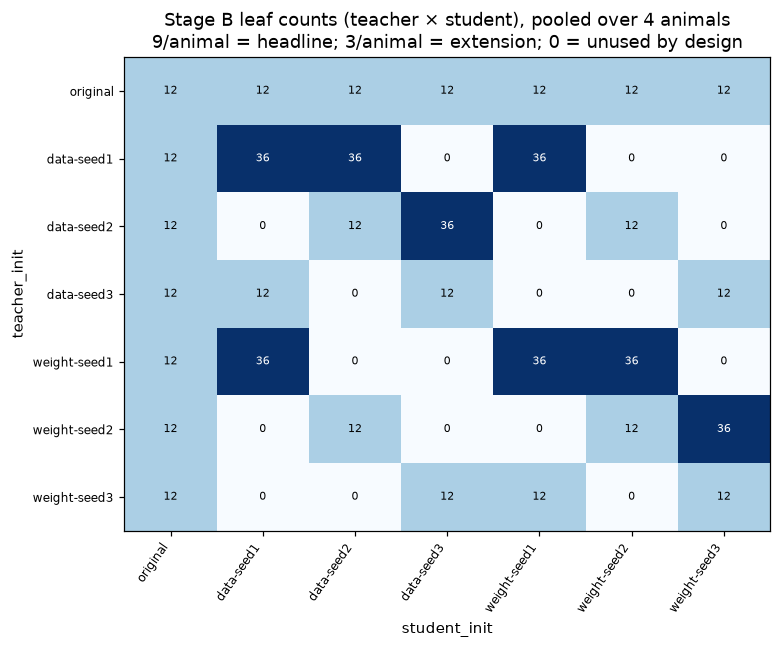

In [6]:
print_scope(treat_m, "Stage B treat leaves after pairing annotate")

grid_n = (
    treat_m.groupby(["teacher_base", "student_base"], dropna=False)
    .size()
    .unstack()
    .reindex(index=BASE_ORDER, columns=BASE_ORDER)
    .fillna(0)
    .astype(int)
)
per_animal = (
    treat_m.groupby("animal")
    .agg(
        n_leaves=("gseed", "size"),
        n_pairings=("pairing", "nunique"),
        n_headline_leaves=("headline", "sum"),
    )
    .reindex(list(ANIMALS))
)
print("Per-animal treat leaves (design: identical):")
display(per_animal)
assert (per_animal["n_pairings"] == 31).all()
assert (per_animal["n_leaves"] == 141).all()

designed = {(p.teacher, p.student) for p in stage_b_pairs()}
empty_cells = [
    (t, s)
    for t in BASE_ORDER
    for s in BASE_ORDER
    if (t, s) not in designed
]
print(f"By-design empty 7×7 cells ({len(empty_cells)} of 49):")
for t, s in empty_cells:
    print(f"  teacher={t}  student={s}")

n_head_cfg = treat_m.loc[treat_m["headline"]].drop_duplicates(
    ["animal", "model", "teacher_tag"]
).shape[0]
n_ext_cfg = treat_m.loc[~treat_m["headline"]].drop_duplicates(
    ["animal", "model", "teacher_tag"]
).shape[0]
print(
    f"headline configs/leaves: {n_head_cfg} / {int(treat_m.headline.sum())}; "
    f"extension: {n_ext_cfg} / {int((~treat_m.headline).sum())}"
)

print_scope(treat_m, "7×7 leaf-count heatmap (pooled over animals)")
fig, ax = plt.subplots(figsize=(7.2, 6.0))
aplots.annotated_heatmap(
    ax,
    grid_n.astype(float),
    cmap="Blues",
    vmin=0,
    vmax=float(grid_n.values.max()),
    fmt="{:.0f}",
    origin="upper",
    empty_facecolor="#f0f0f0",
)
ax.set_title(
    f"Stage B leaf counts (teacher × student), pooled over {len(ANIMALS)} animals\n"
    f"9/animal = headline; 3/animal = extension; 0 = unused by design"
)
ax.set_xlabel("student_init")
ax.set_ylabel("teacher_init")
plt.tight_layout()
plt.show()


## 3. Control floor by student init × animal

**What this measures.** GKD-from-unfinetuned-teacher `p_target` on `test` /
`prob`, one panel per animal. Floors that differ across animals forbid
pooling raw treatment `p_target`. This is floor (b), not the untuned base.


SCOPE: 28 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | GKD control floor, test/prob
Control p_target by animal:


,mean,min,max,std,count
animal,,,,,
cat,0.004261,0.002628,0.007497,0.001574,7
dog,0.008391,0.005715,0.014358,0.002850,7
bear,0.000748,0.000578,0.001283,0.000243,7
eagle,0.000400,0.000138,0.000751,0.000204,7


Animal-mean floor spread (max−min)=0.0080 — do not pool raw p_target across animals.


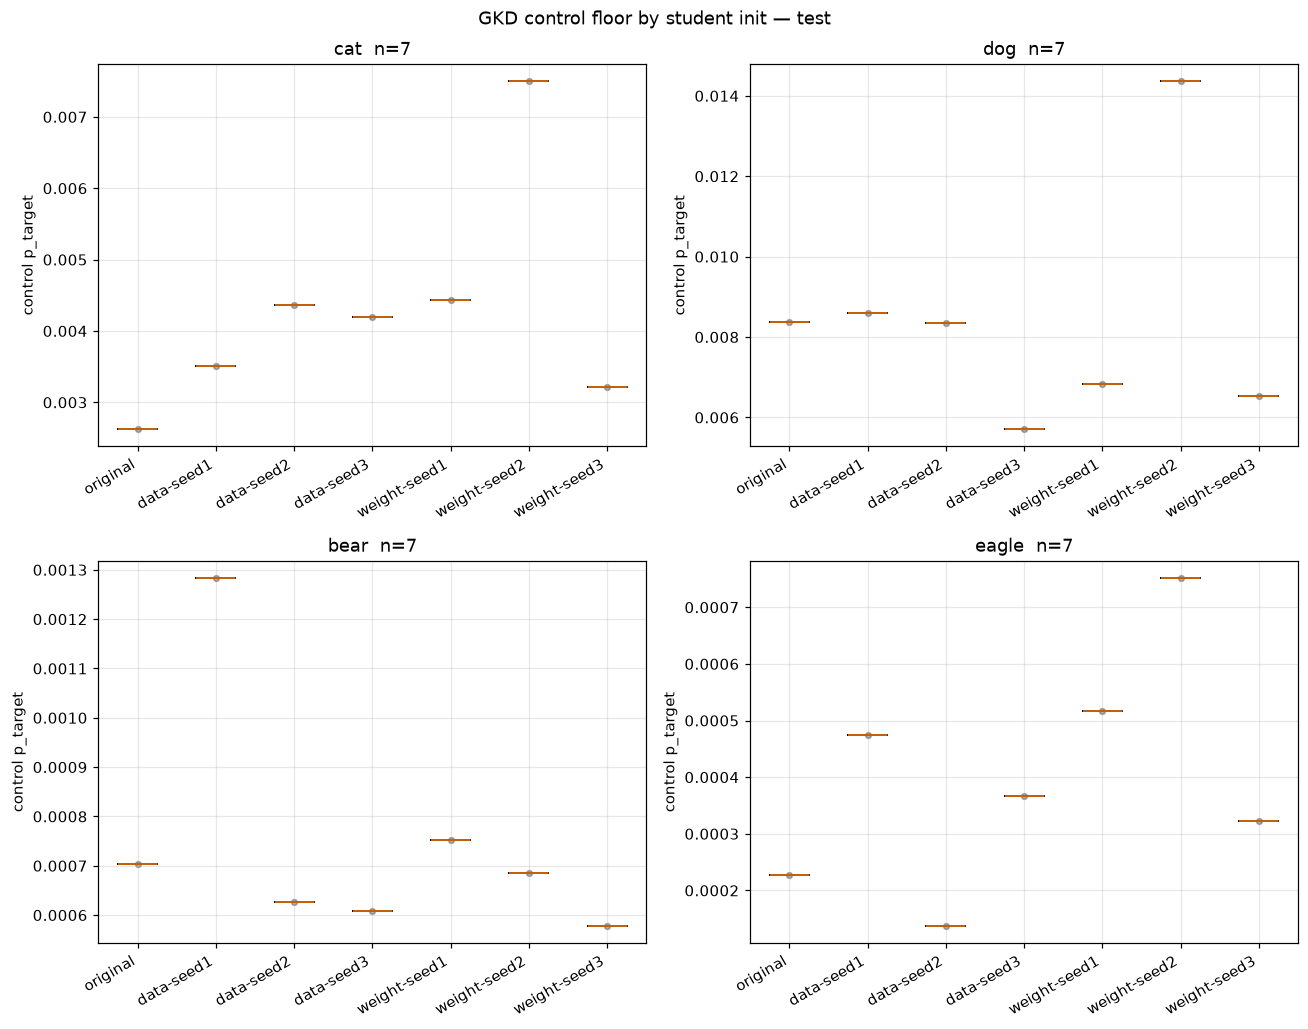

In [7]:
ctrl_pref = annotate_pairing(
    pref[(pref["is_control"]) & (pref["set"] == PRIMARY_SET)].copy()
)
print_scope(ctrl_pref, f"GKD control floor, {PRIMARY_SET}/prob")
print("Control p_target by animal:")
display(
    ctrl_pref.groupby("animal")["p_target"]
    .agg(["mean", "min", "max", "std", "count"])
    .reindex(list(ANIMALS))
)
floor_spread = ctrl_pref.groupby("animal")["p_target"].mean()
print(
    "Animal-mean floor spread "
    f"(max−min)={float(floor_spread.max() - floor_spread.min()):.4f} "
    "— do not pool raw p_target across animals."
)

fig, axes = animal_axes(figsize=(12.0, 9.5))
for ax, animal in zip(axes, ANIMALS):
    sub = ctrl_pref[ctrl_pref["animal"] == animal]
    groups = groups_for_strip(sub, "student_base", "p_target", BASE_ORDER)
    aplots.strip_box(ax, groups, BASE_ORDER, colors=["0.35"] * len(BASE_ORDER), rotation=30)
    ax.set_title(f"{animal}  n={len(sub)}")
    ax.set_ylabel("control p_target")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle(f"GKD control floor by student init — {PRIMARY_SET}")
plt.tight_layout()
plt.show()


## 4. Headline Δ heatmaps

**What this measures.** Mean `subliminal_delta` on `test` / `prob` in the
7×7 teacher × student grid, one panel per animal (2×2, not 1×2). Cell
counts are the number of (already ftseed-collapsed) rows contributing to
that mean. Empty cells are unrun pairings. Raw `p_target` is behind
`DEEP_ANIMAL` so this section does not draw eight always-on panels.


SCOPE: 124 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | subliminal_delta test (ftseed already collapsed)


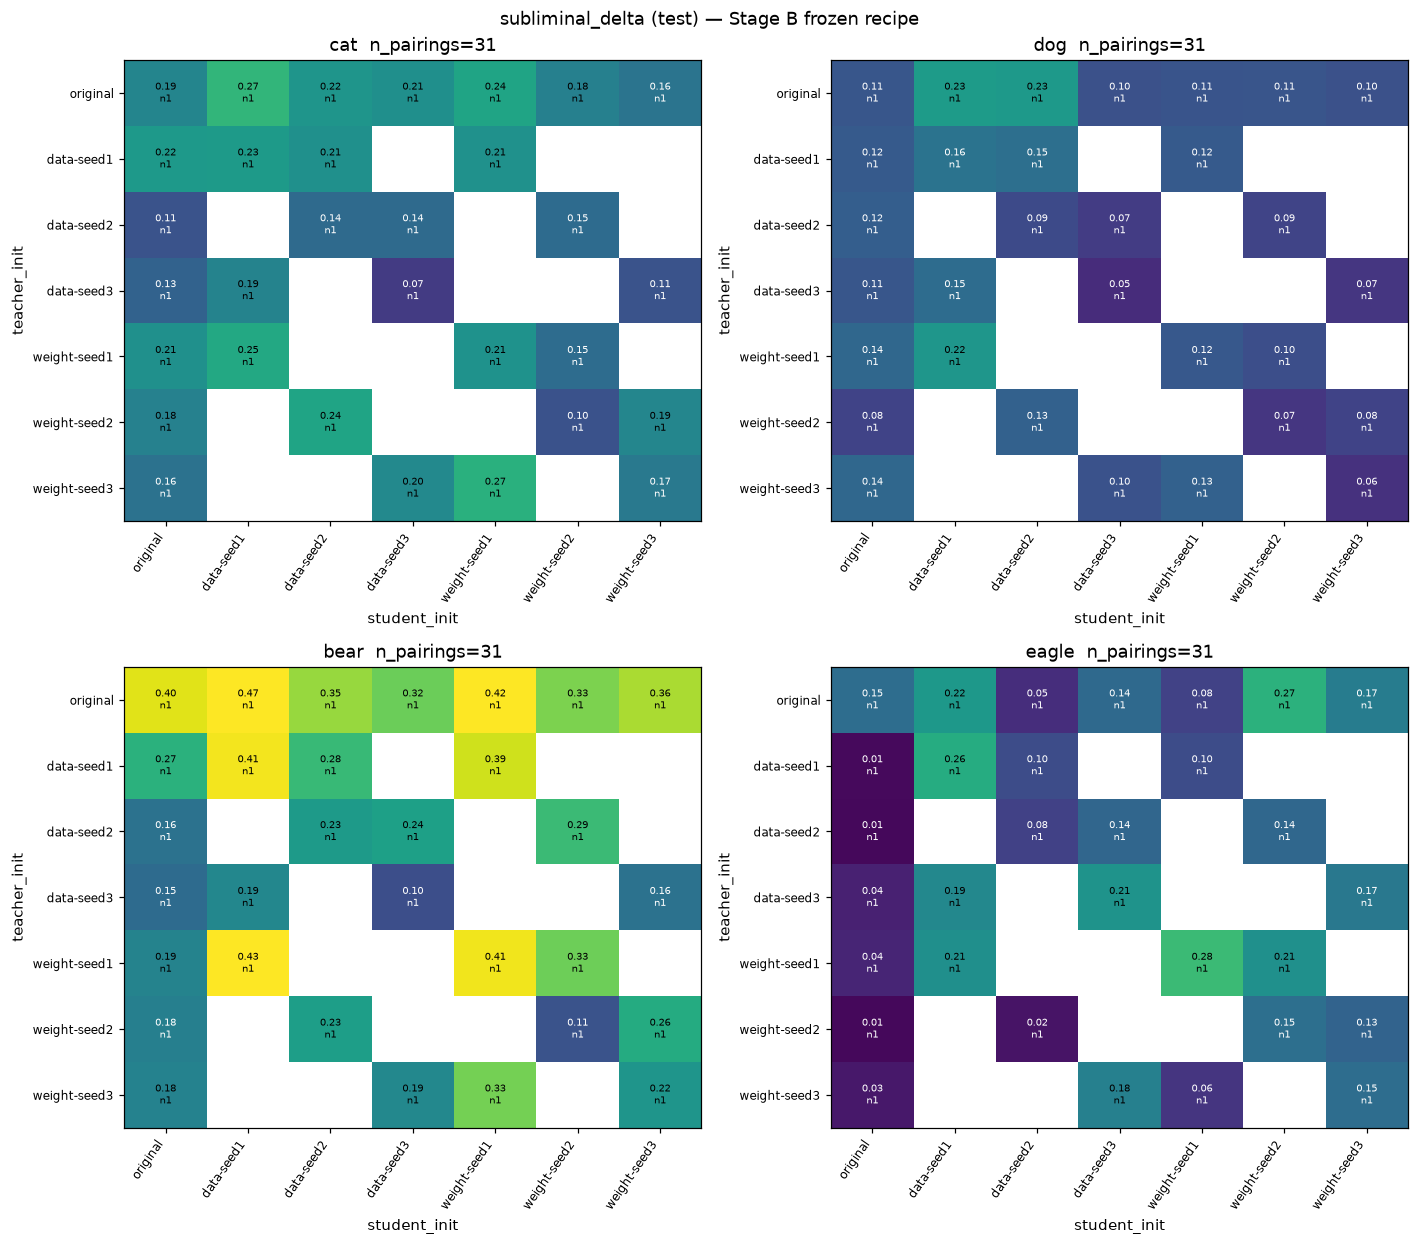

In [8]:
delta = subliminal_delta(pref)
delta_ann = annotate_pairing(delta)
delta_test = delta_ann[delta_ann["set"] == PRIMARY_SET].copy()
assert delta_test.drop_duplicates(["animal", "student_base", "teacher_base"]).shape[0] == (
    31 * len(ANIMALS)
)
print_scope(delta_test, f"subliminal_delta {PRIMARY_SET} (ftseed already collapsed)")

fig, axes = animal_axes(figsize=(13.0, 11.5))
vmax = float(np.nanpercentile(delta_test["subliminal_delta"], 98))
for ax, animal in zip(axes, ANIMALS):
    sub = delta_test[delta_test["animal"] == animal]
    g_delta = (
        sub.pivot_table(
            index="teacher_base",
            columns="student_base",
            values="subliminal_delta",
            aggfunc="mean",
        )
        .reindex(index=BASE_ORDER, columns=BASE_ORDER)
    )
    g_n = (
        sub.groupby(["teacher_base", "student_base"])
        .size()
        .unstack()
        .reindex(index=BASE_ORDER, columns=BASE_ORDER)
    )
    aplots.annotated_heatmap(
        ax,
        g_delta,
        cmap="viridis",
        vmin=0.0,
        vmax=max(vmax, 0.05),
        counts=g_n,
        fmt="{:.2f}",
        origin="upper",
        empty_facecolor="#f4f4f4",
        cell_fontsize=6.5,
    )
    ax.set_title(f"{animal}  n_pairings={sub.pairing.nunique()}")
    ax.set_xlabel("student_init")
    ax.set_ylabel("teacher_init")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle(f"subliminal_delta ({PRIMARY_SET}) — Stage B frozen recipe")
plt.tight_layout()
plt.show()


DEEP_ANIMAL='cat' — raw p_target_treatment companion (not the Cloud effect)
SCOPE: 31 configs | 1 animal(s) x 7 base model(s) | seeds pre-averaged | raw p_target_treatment cat test


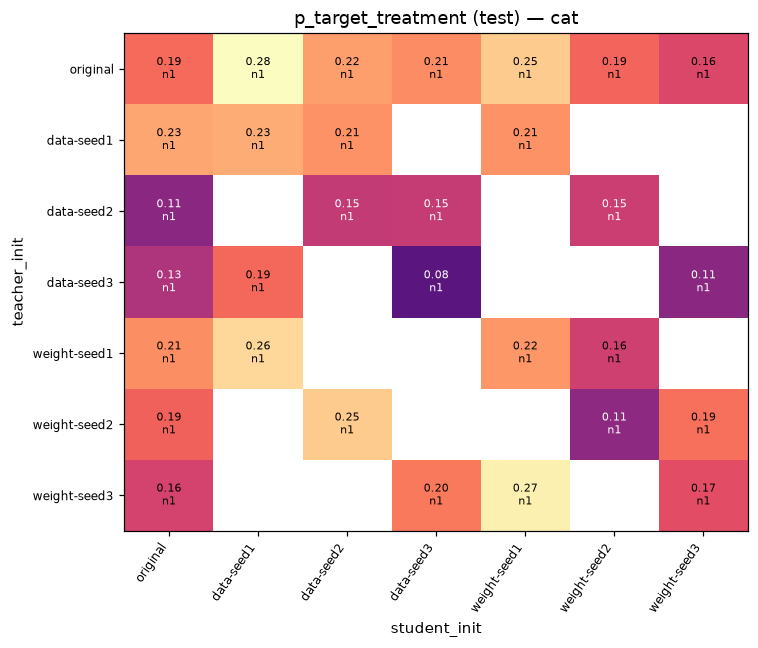

In [9]:
print(f"DEEP_ANIMAL={DEEP_ANIMAL!r} — raw p_target_treatment companion (not the Cloud effect)")
sub = delta_test[delta_test["animal"] == DEEP_ANIMAL]
print_scope(sub, f"raw p_target_treatment {DEEP_ANIMAL} {PRIMARY_SET}")
g_raw = (
    sub.pivot_table(
        index="teacher_base",
        columns="student_base",
        values="p_target_treatment",
        aggfunc="mean",
    )
    .reindex(index=BASE_ORDER, columns=BASE_ORDER)
)
g_n = (
    sub.groupby(["teacher_base", "student_base"])
    .size()
    .unstack()
    .reindex(index=BASE_ORDER, columns=BASE_ORDER)
)
fig, ax = plt.subplots(figsize=(7.0, 6.0))
aplots.annotated_heatmap(
    ax,
    g_raw,
    cmap="magma",
    vmin=0.0,
    vmax=float(np.nanmax(g_raw.values)) if np.isfinite(g_raw.to_numpy()).any() else 1.0,
    counts=g_n,
    fmt="{:.2f}",
    origin="upper",
    empty_facecolor="#f4f4f4",
)
ax.set_title(f"p_target_treatment ({PRIMARY_SET}) — {DEEP_ANIMAL}")
ax.set_xlabel("student_init")
ax.set_ylabel("teacher_init")
plt.tight_layout()
plt.show()


## 5. The 2×2 corner factorial

**What this measures.** Mean `subliminal_delta` (`test` / `prob`) by the
init × stream corner, per animal and pooled (within-animal z-scores).
Intervals are **pairing-cluster** percentile bootstraps. Presented as a
**replication surface**. H1/H2 adjudication is out of scope. Any pairing
ranking is **post-hoc** (no Stage-B pre-registration). Headline and
extension are tabulated separately and never pooled into one CI.

**Read the intervals with care.** Corners in the headline tier hold only
2 pairings each, and a cluster bootstrap over 2 clusters cannot express
between-pairing spread — the interval collapses toward the mean and
`p_boot` saturates at 0. Rows flagged `ci_degenerate` are descriptive
means, not precisely estimated effects; corner *contrasts* at this
cluster count are underpowered. The extension tier has more pairings per
corner and is the better place to look at spread.


SCOPE: 124 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | pairing-level Δ test


Headline (3×3) pairing-cluster CIs — POST-HOC, not a pre-registered ranking:


,animal,corner,mean,ci_lo,ci_hi,n_pairings,p_boot,ci_degenerate,tier
0,cat,shared_init_shared_stream,0.219742,0.213001,0.226483,2,0.0,True,headline
1,cat,diff_init_shared_stream,0.169566,0.147771,0.191360,2,0.0,True,headline
2,cat,shared_init_diff_stream,0.177254,0.144755,0.209753,2,0.0,True,headline
3,cat,diff_init_diff_stream,0.231079,0.210295,0.251863,2,0.0,True,headline
4,dog,shared_init_shared_stream,0.136778,0.115336,0.158220,2,0.0,True,headline
5,dog,diff_init_shared_stream,0.092174,0.083745,0.100604,2,0.0,True,headline
6,dog,shared_init_diff_stream,0.113287,0.074391,0.152183,2,0.0,True,headline
7,dog,diff_init_diff_stream,0.168582,0.117800,0.219364,2,0.0,True,headline
8,bear,shared_init_shared_stream,0.408953,0.408349,0.409556,2,0.0,True,headline
9,bear,diff_init_shared_stream,0.291081,0.257078,0.325084,2,0.0,True,headline


Extension (1×3) pairing-cluster CIs — do not pool with headline:


,animal,corner,mean,ci_lo,ci_hi,n_pairings,p_boot,ci_degenerate,tier
0,cat,shared_init_shared_stream,0.135642,0.098084,0.171696,5,0.0,False,extension
1,cat,diff_init_shared_stream,0.200218,0.173387,0.229256,7,0.0,False,extension
2,cat,shared_init_diff_stream,0.192747,0.152985,0.229795,7,0.0,False,extension
3,cat,diff_init_diff_stream,0.172985,0.126125,0.219845,4,0.0,False,extension
4,dog,shared_init_shared_stream,0.076349,0.057631,0.097189,5,0.0,False,extension
5,dog,diff_init_shared_stream,0.116394,0.102175,0.129924,7,0.0,False,extension
6,dog,shared_init_diff_stream,0.151275,0.117233,0.191279,7,0.0,False,extension
7,dog,diff_init_diff_stream,0.096571,0.075285,0.118977,4,0.0,False,extension
8,bear,shared_init_shared_stream,0.210278,0.126484,0.304952,5,0.0,False,extension
9,bear,diff_init_shared_stream,0.285903,0.218042,0.354076,7,0.0,False,extension



CAVEAT (headline): 16 of 16 corners have n_pairings<3 (min=2). A pairing-cluster bootstrap over so few clusters cannot express between-pairing spread: those intervals collapse toward the point estimate and p_boot saturates at 0. Read them as descriptive means, NOT as evidence of a precisely estimated corner effect. Corner contrasts at this cluster count are underpowered.


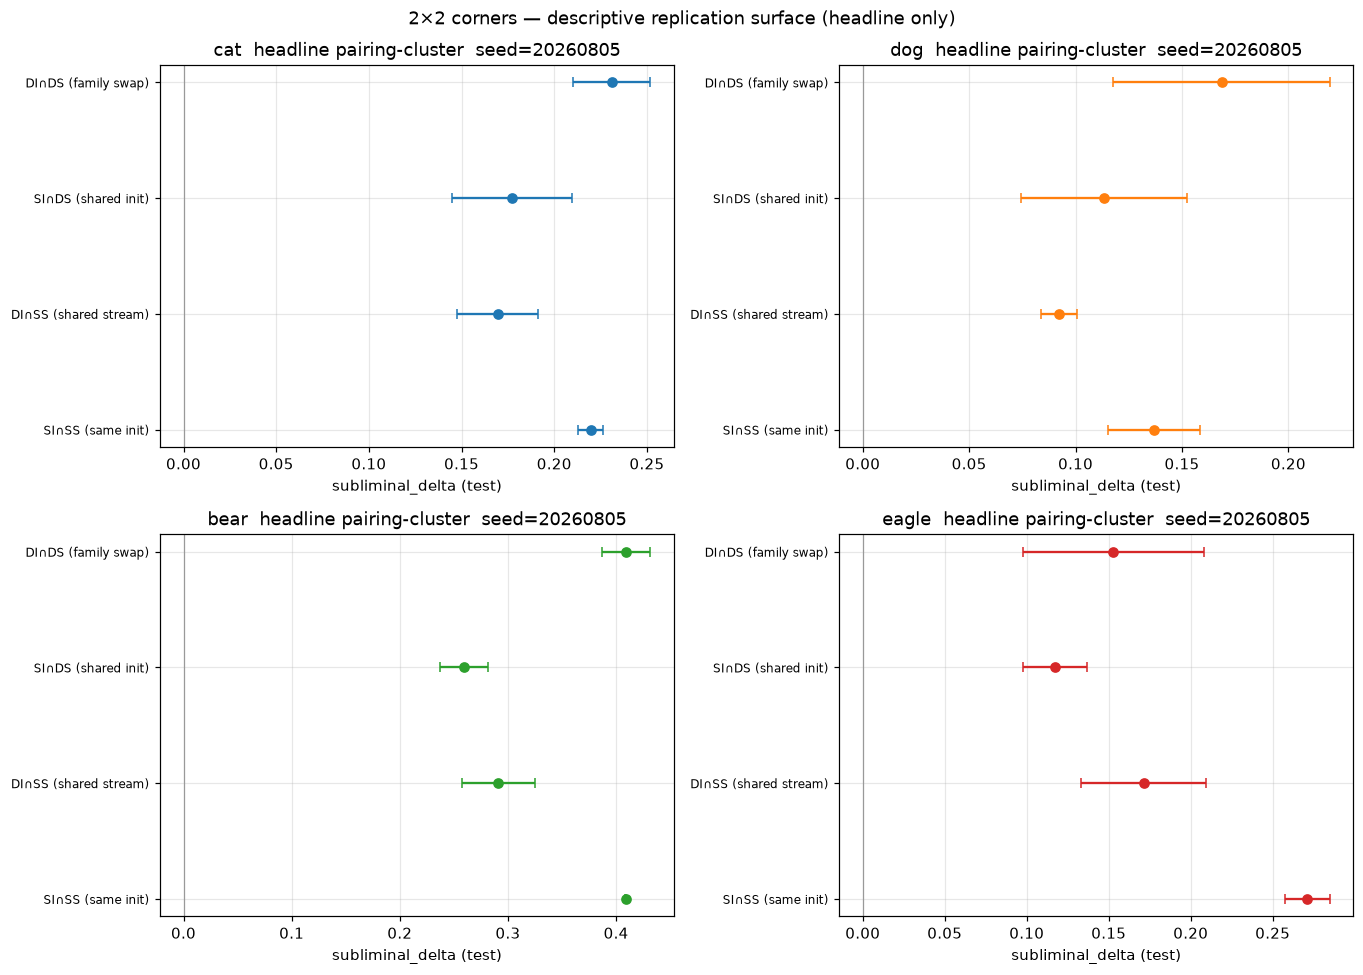

Pooled (within-animal z, headline) corner means:


,animal,corner,mean,ci_lo,ci_hi,n_pairings,p_boot,ci_degenerate
0,pooled,shared_init_shared_stream,0.726131,0.612786,0.839475,2,0.0000,True
1,pooled,diff_init_shared_stream,-0.579316,-0.720527,-0.438105,2,0.0000,True
2,pooled,shared_init_diff_stream,-0.706726,-1.135117,-0.278334,2,0.0000,True
3,pooled,diff_init_diff_stream,0.559911,-0.113511,1.233333,2,0.5026,True


No H1/H2 verdict is computed. Ranking pairings or corners by these means is post-hoc.


In [10]:
pd_delta = pairing_delta_frame(delta, PRIMARY_SET)
print_scope(pd_delta, f"pairing-level Δ {PRIMARY_SET}")

corner_tables = []
for animal in ANIMALS:
    corner_tables.append(
        corner_bootstrap_table(
            pd_delta, animal=animal, headline_only=True, n_boot=N_BOOT, seed=BOOTSTRAP_SEED
        )
    )
    corner_tables.append(
        corner_bootstrap_table(
            pd_delta, animal=animal, headline_only=False, n_boot=N_BOOT, seed=BOOTSTRAP_SEED
        ).assign(tier="extension")
    )
headline_ci = pd.concat(
    [t.assign(tier="headline") for t in corner_tables[0::2]], ignore_index=True
)
extension_ci = pd.concat(corner_tables[1::2], ignore_index=True)
print("Headline (3×3) pairing-cluster CIs — POST-HOC, not a pre-registered ranking:")
display(headline_ci)
print("Extension (1×3) pairing-cluster CIs — do not pool with headline:")
display(extension_ci)

for tier_name, tier_ci in (("headline", headline_ci), ("extension", extension_ci)):
    deg = tier_ci[tier_ci["ci_degenerate"] & (tier_ci["n_pairings"] > 0)]
    if not deg.empty:
        print(
            f"\nCAVEAT ({tier_name}): {len(deg)} of {len(tier_ci)} corners have "
            f"n_pairings<3 (min={int(deg['n_pairings'].min())}). A pairing-cluster "
            "bootstrap over so few clusters cannot express between-pairing spread: "
            "those intervals collapse toward the point estimate and p_boot "
            "saturates at 0. Read them as descriptive means, NOT as evidence of a "
            "precisely estimated corner effect. Corner contrasts at this cluster "
            "count are underpowered."
        )

fig, axes = animal_axes(figsize=(12.5, 9.0))
for ax, animal in zip(axes, ANIMALS):
    sub = headline_ci[headline_ci["animal"] == animal].set_index("corner").reindex(CORNER_ORDER)
    y = np.arange(len(CORNER_ORDER))
    ax.errorbar(
        sub["mean"],
        y,
        xerr=[sub["mean"] - sub["ci_lo"], sub["ci_hi"] - sub["mean"]],
        fmt="o",
        color=ANIMAL_COLORS.get(animal, "C0"),
        capsize=3,
    )
    ax.axvline(0, color="0.6", lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([CORNER_SHORT[c] for c in CORNER_ORDER], fontsize=8)
    ax.set_xlabel(f"subliminal_delta ({PRIMARY_SET})")
    ax.set_title(f"{animal}  headline pairing-cluster  seed={BOOTSTRAP_SEED}")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("2×2 corners — descriptive replication surface (headline only)")
plt.tight_layout()
plt.show()

z = standardize_within_animal(pd_delta.loc[pd_delta["headline"]].copy(), "subliminal_delta")
z["subliminal_delta"] = z["subliminal_delta_z"]
pooled = corner_bootstrap_table(z, animal=None, headline_only=True, n_boot=N_BOOT, seed=BOOTSTRAP_SEED)
print("Pooled (within-animal z, headline) corner means:")
display(pooled)
print(
    "No H1/H2 verdict is computed. Ranking pairings or corners by these means "
    "is post-hoc."
)


## 6. Primary — Cloud shared-init test

**What this measures.** Cloud et al. claim subliminal learning requires a
shared teacher/student initialization. Per animal: same-init vs cross-init
mean Δ, `cross_positive_frac` (fraction of cross-init pairings with Δ>0),
and sign tests. The earlier two-animal run found `cross_positive_frac=1.0`,
contradicting Cloud. This section tests whether that replicates at four
animals. Headline pairings are the primary test; extension is reported
separately.


SCOPE: 32 configs | 4 animal(s) x 6 base model(s) | seeds pre-averaged | Cloud test, headline pairings
Cloud shared-init test (pairing-cluster CIs; sign test on pairing Δs):


,animal,tier,n_same,n_cross,same_mean,same_ci_lo,same_ci_hi,cross_mean,cross_ci_lo,cross_ci_hi,cross_positive_frac,cross_sign_n_pos,cross_sign_n,cross_sign_p,same_sign_p
0,cat,headline,2,6,0.219742,0.213001,0.226483,0.192633,0.163852,0.220995,1.0,6,6,0.015625,0.25000
1,dog,headline,2,6,0.136778,0.115336,0.158220,0.124681,0.090363,0.167077,1.0,6,6,0.015625,0.25000
2,bear,headline,2,6,0.408953,0.408349,0.409556,0.319920,0.266029,0.377583,1.0,6,6,0.015625,0.25000
3,eagle,headline,2,6,0.271104,0.257492,0.284716,0.147124,0.110755,0.184139,1.0,6,6,0.015625,0.25000
4,cat,extension,5,18,0.135642,0.099589,0.171696,0.191261,0.168413,0.213335,1.0,18,18,0.000004,0.03125
5,dog,extension,5,18,0.076349,0.057631,0.097189,0.125553,0.108245,0.146042,1.0,18,18,0.000004,0.03125
6,bear,extension,5,18,0.210278,0.126484,0.306370,0.265641,0.222006,0.311002,1.0,18,18,0.000004,0.03125
7,eagle,extension,5,18,0.149160,0.108302,0.188418,0.102815,0.066584,0.141402,1.0,18,18,0.000004,0.03125


Headline cross_positive_frac by animal: {'cat': 1.0, 'dog': 1.0, 'bear': 1.0, 'eagle': 1.0}
Earlier 2-animal run: cross_positive_frac=1.0 on cat+dog. Replication at four animals is the headline claim of this notebook.


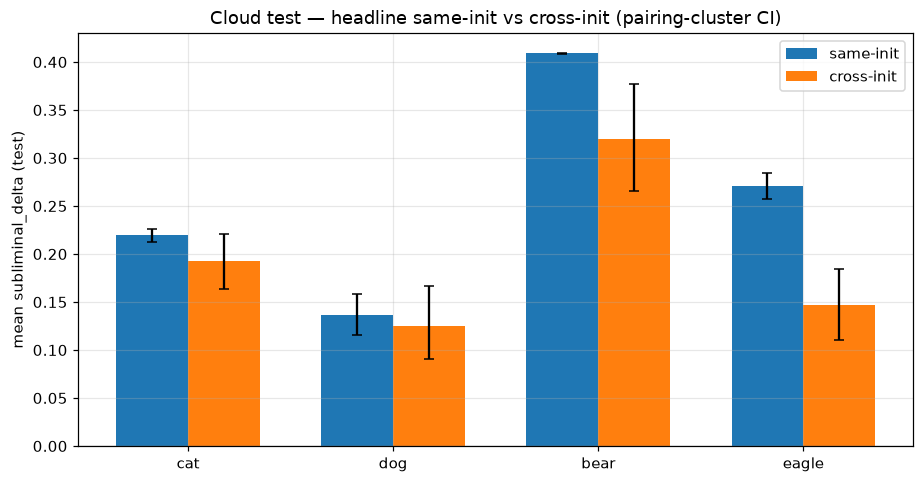

In [11]:
def cloud_rows(frame: pd.DataFrame, *, tier: str) -> pd.DataFrame:
    rows: list[dict[str, Any]] = []
    for animal in ANIMALS:
        sub = frame[frame["animal"] == animal]
        same = sub.loc[sub["same_init_pair"], "subliminal_delta"]
        cross = sub.loc[~sub["same_init_pair"], "subliminal_delta"]
        same_est = pairing_cluster_ci(same.values) if len(same) else None
        cross_est = pairing_cluster_ci(cross.values) if len(cross) else None
        st_cross = sign_test(list(cross), 0.0, "greater")
        st_same = sign_test(list(same), 0.0, "greater")
        rows.append(
            {
                "animal": animal,
                "tier": tier,
                "n_same": int(same.size),
                "n_cross": int(cross.size),
                "same_mean": float(same.mean()) if len(same) else np.nan,
                "same_ci_lo": same_est.ci_low if same_est else np.nan,
                "same_ci_hi": same_est.ci_high if same_est else np.nan,
                "cross_mean": float(cross.mean()) if len(cross) else np.nan,
                "cross_ci_lo": cross_est.ci_low if cross_est else np.nan,
                "cross_ci_hi": cross_est.ci_high if cross_est else np.nan,
                "cross_positive_frac": float((cross > 0).mean()) if len(cross) else np.nan,
                "cross_sign_n_pos": st_cross.n_positive,
                "cross_sign_n": st_cross.n_effective,
                "cross_sign_p": st_cross.p_value,
                "same_sign_p": st_same.p_value,
            }
        )
    return pd.DataFrame(rows)


cloud_h = cloud_rows(pd_delta[pd_delta["headline"]], tier="headline")
cloud_e = cloud_rows(pd_delta[~pd_delta["headline"]], tier="extension")
cloud = pd.concat([cloud_h, cloud_e], ignore_index=True)
print_scope(pd_delta[pd_delta["headline"]], "Cloud test, headline pairings")
print("Cloud shared-init test (pairing-cluster CIs; sign test on pairing Δs):")
display(cloud)

print(
    "Headline cross_positive_frac by animal:",
    {r.animal: r.cross_positive_frac for r in cloud_h.itertuples()},
)
print(
    "Earlier 2-animal run: cross_positive_frac=1.0 on cat+dog. "
    "Replication at four animals is the headline claim of this notebook."
)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
xpos = np.arange(len(ANIMALS))
width = 0.35
ax.bar(
    xpos - width / 2,
    cloud_h["same_mean"],
    width,
    yerr=np.vstack([
        cloud_h["same_mean"] - cloud_h["same_ci_lo"],
        cloud_h["same_ci_hi"] - cloud_h["same_mean"],
    ]),
    label="same-init",
    color="C0",
    capsize=3,
)
ax.bar(
    xpos + width / 2,
    cloud_h["cross_mean"],
    width,
    yerr=np.vstack([
        cloud_h["cross_mean"] - cloud_h["cross_ci_lo"],
        cloud_h["cross_ci_hi"] - cloud_h["cross_mean"],
    ]),
    label="cross-init",
    color="C1",
    capsize=3,
)
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(list(ANIMALS))
ax.set_ylabel(f"mean subliminal_delta ({PRIMARY_SET})")
ax.set_title("Cloud test — headline same-init vs cross-init (pairing-cluster CI)")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Animal heterogeneity of Δ

**What this measures.** Whether animal is a real factor rather than a
label to pool over. Variance components over animal / pairing / gseed,
plus Kruskal-Wallis on pairing-mean Δ and a pairing-blocked Friedman test
on the 31 pairings shared by all four animals. Report per-animal; never
pooled-only.


SCOPE: 564 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | gseed-level paired Δ test
Variance components (order animal → pairing → gseed):
{'animal': 0.4291, 'pairing': 0.2508, 'gseed': 0.0013, 'residual': 0.3189} n_obs 564
Kruskal-Wallis on pairing-mean Δ across animals: H=48.297 p=1.841e-10
Friedman (pairing-blocked, 31 pairings × 4 animals): Q=52.858 p=1.966e-11
Per-animal pairing-mean Δ:


,mean,std,count
animal,,,
cat,0.184393,0.050132,31
dog,0.118173,0.044403,31
bear,0.276463,0.104063,31
eagle,0.129723,0.081180,31


SCOPE: 124 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | animal heterogeneity strip


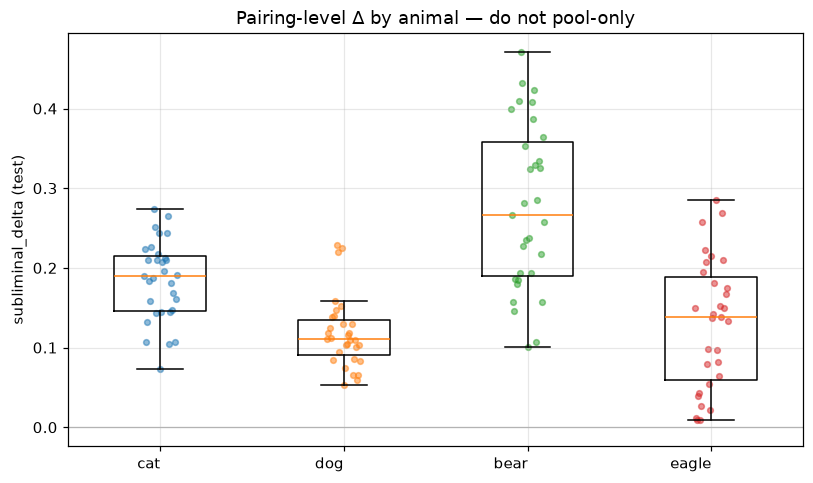

In [12]:
def pairing_seed_deltas(pref_frame: pd.DataFrame, prompt_set: str = PRIMARY_SET) -> pd.DataFrame:
    """One row per (animal, pairing, teacher_ftseed, gseed) of paired Δ."""
    treat = annotate_pairing(
        pref_frame[(~pref_frame["is_control"]) & (pref_frame["set"] == prompt_set)].copy()
    )
    ctrl = pref_frame[(pref_frame["is_control"]) & (pref_frame["set"] == prompt_set)]
    ctrl_map: dict[tuple[str, str], dict] = {}
    for row in ctrl.itertuples(index=False):
        ctrl_map[(row.animal, row.model)] = row.per_seed_p_target or {}
    rows: list[dict[str, Any]] = []
    for row in treat.itertuples(index=False):
        cseeds = ctrl_map.get((row.animal, row.model), {})
        tseeds = row.per_seed_p_target or {}
        for gs, tp in tseeds.items():
            if gs not in cseeds or tp is None or cseeds[gs] is None:
                continue
            rows.append(
                {
                    "animal": row.animal,
                    "model": row.model,
                    "student_base": row.student_base,
                    "teacher_base": row.teacher_base,
                    "pairing": row.pairing,
                    "corner": row.corner,
                    "headline": row.headline,
                    "teacher_ftseed": row.teacher_ftseed,
                    "gseed": int(gs),
                    "subliminal_delta": float(tp) - float(cseeds[gs]),
                }
            )
    return pd.DataFrame(rows)


seed_delta = pairing_seed_deltas(pref, PRIMARY_SET)
print_scope(seed_delta, f"gseed-level paired Δ {PRIMARY_SET}")
vc_df = seed_delta.dropna(subset=["subliminal_delta"]).copy()
vc = astats.variance_components(
    vc_df["subliminal_delta"].to_numpy(),
    {
        "animal": vc_df["animal"].tolist(),
        "pairing": vc_df["pairing"].tolist(),
        "gseed": vc_df["gseed"].astype(str).tolist(),
    },
    order=("animal", "pairing", "gseed"),
)
print("Variance components (order animal → pairing → gseed):")
print({k: round(v, 4) for k, v in vc.fractions.items()}, "n_obs", vc.n_obs)

pairing_means_animal = (
    pd_delta.groupby(["animal", "pairing"], dropna=False)["subliminal_delta"]
    .mean()
    .reset_index()
)
kw_groups = [
    pairing_means_animal.loc[pairing_means_animal["animal"] == a, "subliminal_delta"].to_numpy()
    for a in ANIMALS
]
kw = kruskal(*kw_groups)
print(f"Kruskal-Wallis on pairing-mean Δ across animals: H={kw.statistic:.3f} p={kw.pvalue:.4g}")

wide = pairing_means_animal.pivot(index="pairing", columns="animal", values="subliminal_delta")
wide = wide.reindex(columns=list(ANIMALS)).dropna()
fried = friedmanchisquare(*[wide[a].to_numpy() for a in ANIMALS])
print(
    f"Friedman (pairing-blocked, {len(wide)} pairings × {len(ANIMALS)} animals): "
    f"Q={fried.statistic:.3f} p={fried.pvalue:.4g}"
)

print("Per-animal pairing-mean Δ:")
display(
    pd_delta.groupby("animal")["subliminal_delta"]
    .agg(["mean", "std", "count"])
    .reindex(list(ANIMALS))
)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
aplots.strip_box(
    ax,
    groups_for_strip(pd_delta, "animal", "subliminal_delta", ANIMALS),
    list(ANIMALS),
    colors=[ANIMAL_COLORS[a] for a in ANIMALS],
    zero_line=True,
    rotation=0,
)
ax.set_ylabel(f"subliminal_delta ({PRIMARY_SET})")
ax.set_title("Pairing-level Δ by animal — do not pool-only")
print_scope(pd_delta, "animal heterogeneity strip")
plt.tight_layout()
plt.show()


## 8. Teacher-strength confound

**What this measures.** Teacher `p_target` (favorite, mean over ftseeds)
versus student Δ. The n=4 animal-mean Spearman is underpowered and must
not be called significant. The powered unit is the 28 (animal, init)
teacher cells. Dog teachers are a symlink to an older run-set — data
bytes match, provenance differs. Eagle having a strong teacher but low
transfer efficiency is the reason heterogeneity is not “just teacher
quality.”


Teacher tree: /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/sdf_teachers/20260809_breadth4-teachers_160m dog symlink: True
  dog resolves to /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/sdf_teachers/20260726_crossinit_160m/dog
  CAVEAT: dog teachers are reused from an older run-set (stale absolute paths inside those manifests; sha256-identical bytes). Filter param_tag strictly; extra legacy full-FT / other-tag cells exist behind the symlink.


SCOPE: 28 configs | 4 animal(s) x 0 base model(s) | seeds pre-averaged | T1 teacher favorite p_target (animal × init)
Teacher strength 28-cell table:


animal,cat,dog,bear,eagle
teacher_base,,,,
original,0.092893,0.091781,0.260051,0.118189
data-seed1,0.155614,0.105427,0.307197,0.277680
data-seed2,0.082006,0.140078,0.254134,0.233686
data-seed3,0.059245,0.048107,0.116601,0.209758
weight-seed1,0.142208,0.061765,0.292256,0.279528
weight-seed2,0.102674,0.078872,0.164494,0.243364
weight-seed3,0.118962,0.068968,0.221485,0.220415


spread min=0.0481 max=0.3072 ratio=6.39x
per-animal mean over 7 inits:
animal
cat      0.107657
dog      0.085000
bear     0.230888
eagle    0.226089
Name: teacher_p_target, dtype: float64
SCOPE: 124 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | pairing Δ vs teacher strength


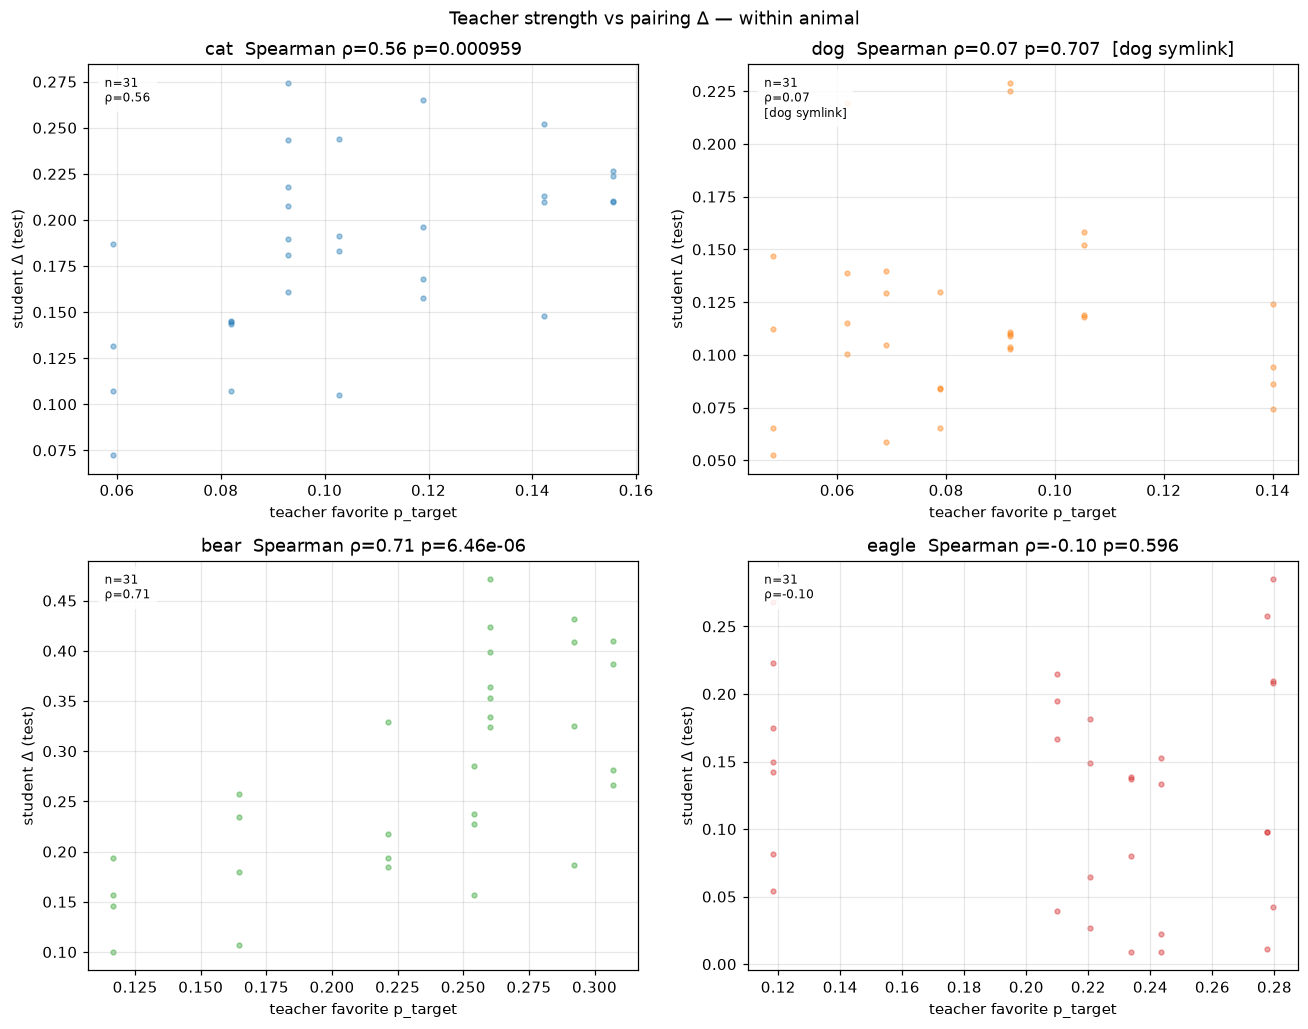

cat OLS Δ ~ teacher_p: slope=0.850 R2=0.269 n=31
dog OLS Δ ~ teacher_p: slope=-0.003 R2=0.000 n=31
bear OLS Δ ~ teacher_p: slope=1.131 R2=0.458 n=31
eagle OLS Δ ~ teacher_p: slope=-0.160 R2=0.013 n=31
n=4 animal-mean Spearman(teacher, freeze Δ): ρ=0.80 p=0.2 — underpowered, must not be called significant.
transfer efficiency (freeze Δ / mean teacher p): {'cat': 2.41, 'dog': 1.923, 'bear': 1.844, 'eagle': 1.022}
n=28 (animal, init) Spearman(teacher, mean pairing Δ): ρ=0.44 p=0.0207
SCOPE: 28 configs | 4 animal(s) x 0 base model(s) | seeds pre-averaged | 28 teacher cells


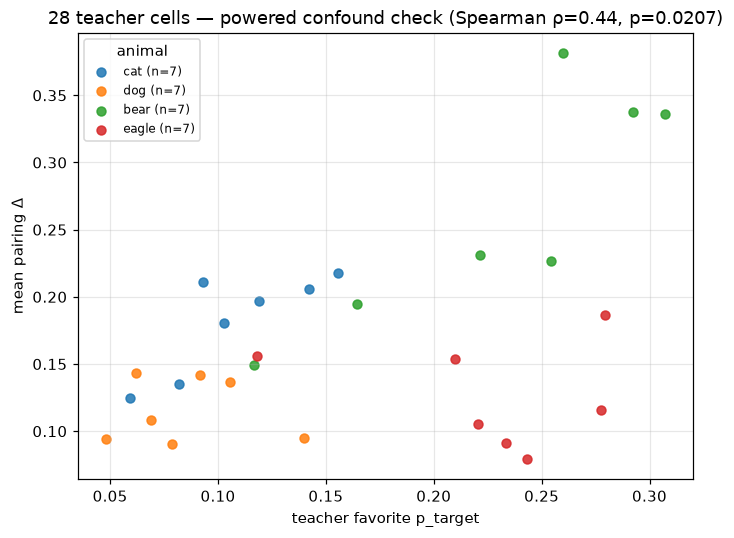

In [13]:
print("Teacher tree:", TEACHER_TREE, "dog symlink:", (TEACHER_TREE / "dog").is_symlink())
if (TEACHER_TREE / "dog").is_symlink():
    print("  dog resolves to", (TEACHER_TREE / "dog").resolve())
    print(
        "  CAVEAT: dog teachers are reused from an older run-set "
        "(stale absolute paths inside those manifests; sha256-identical bytes). "
        "Filter param_tag strictly; extra legacy full-FT / other-tag cells exist "
        "behind the symlink."
    )

tpref = load_sdf_preference_results(OUTPUT_ROOT, subdir=TEACHER_SUBDIR)
if "dog" not in set(tpref["animal"]) and (TEACHER_TREE / "dog").exists():
    src = (TEACHER_TREE / "dog").resolve()
    alt_sub = str(src.parent.relative_to(OUTPUT_ROOT))
    print(f"dog missing from default glob; reloading via {alt_sub}")
    dog_pref = load_sdf_preference_results(
        OUTPUT_ROOT, subdir=alt_sub, animals=["dog"]
    )
    tpref = pd.concat([tpref, dog_pref], ignore_index=True)

tpref_f = tpref[
    (tpref["param_tag"] == TEACHER_PARAM_TAG_LORA) & (tpref["set"] == "favorite")
].copy()
tpref_f["teacher_base"] = tpref_f["model"].map(MODEL_TO_LABEL)
if tpref_f["teacher_base"].isna().any():
    raise ValueError(
        f"unmapped teacher models: {sorted(tpref_f.loc[tpref_f.teacher_base.isna(), 'model'].unique())}"
    )
teacher_28 = (
    tpref_f.groupby(["animal", "teacher_base"], dropna=False)
    .agg(teacher_p_target=("p_target", "mean"), n_seeds=("n_seeds", "first"))
    .reset_index()
)
print_scope(teacher_28, "T1 teacher favorite p_target (animal × init)")
print("Teacher strength 28-cell table:")
display(
    teacher_28.pivot(index="teacher_base", columns="animal", values="teacher_p_target")
    .reindex(index=BASE_ORDER, columns=list(ANIMALS))
)
print(
    "spread "
    f"min={teacher_28.teacher_p_target.min():.4f} "
    f"max={teacher_28.teacher_p_target.max():.4f} "
    f"ratio={teacher_28.teacher_p_target.max() / teacher_28.teacher_p_target.min():.2f}x"
)
print("per-animal mean over 7 inits:")
print(teacher_28.groupby("animal")["teacher_p_target"].mean().reindex(list(ANIMALS)))

# Join pairing Δ to the teacher cell (animal, teacher_base).
pair_teacher = pd_delta.merge(
    teacher_28, on=["animal", "teacher_base"], how="left"
)
assert pair_teacher["teacher_p_target"].notna().all()
pair_teacher["transfer_efficiency"] = [
    transfer_efficiency(d, p)
    for d, p in zip(pair_teacher["subliminal_delta"], pair_teacher["teacher_p_target"])
]

print_scope(pair_teacher, "pairing Δ vs teacher strength")
fig, axes = animal_axes(figsize=(12.0, 9.5))
for ax, animal in zip(axes, ANIMALS):
    sub = pair_teacher[pair_teacher["animal"] == animal]
    note = "  [dog symlink]" if animal == "dog" else ""
    aplots.identity_scatter(
        ax,
        sub,
        "teacher_p_target",
        "subliminal_delta",
        stat="spearman",
        diag_lim=None,
        title_stats=True,
        textbox=True,
        color=ANIMAL_COLORS[animal],
        extra_lines=[note.strip()] if note else None,
    )
    rho, pval = spearmanr(sub["teacher_p_target"], sub["subliminal_delta"])
    ax.set_title(f"{animal}  Spearman ρ={rho:.2f} p={pval:.3g}{note}")
    ax.set_xlabel("teacher favorite p_target")
    ax.set_ylabel(f"student Δ ({PRIMARY_SET})")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("Teacher strength vs pairing Δ — within animal")
plt.tight_layout()
plt.show()

# OLS residualization within animal.
resid_rows = []
for animal in ANIMALS:
    sub = pair_teacher[pair_teacher["animal"] == animal]
    x = sm.add_constant(sub["teacher_p_target"].to_numpy())
    y = sub["subliminal_delta"].to_numpy()
    fit = sm.OLS(y, x).fit()
    tmp = sub.copy()
    tmp["delta_resid"] = fit.resid
    resid_rows.append(tmp)
    print(
        f"{animal} OLS Δ ~ teacher_p: slope={fit.params[1]:.3f} "
        f"R2={fit.rsquared:.3f} n={int(fit.nobs)}"
    )
resid = pd.concat(resid_rows, ignore_index=True)

# n=4 underpowered animal-mean Spearman (freeze per-animal Δ vs mean teacher).
freeze_delta = pd.Series(freeze["winner"]["per_animal_delta"], dtype=float)
t_mean = teacher_28.groupby("animal")["teacher_p_target"].mean().reindex(freeze_delta.index)
rho4, p4 = spearmanr(t_mean.to_numpy(), freeze_delta.to_numpy())
print(
    f"n=4 animal-mean Spearman(teacher, freeze Δ): ρ={rho4:.2f} p={p4:.3g} "
    "— underpowered, must not be called significant."
)
eff4 = {
    a: transfer_efficiency(float(freeze_delta[a]), float(t_mean[a]))
    for a in ANIMALS
}
print("transfer efficiency (freeze Δ / mean teacher p):", {a: round(v, 3) for a, v in eff4.items()})

# Powered 28-cell version: mean pairing Δ for pairings that use that teacher init.
cell_28 = (
    pair_teacher.groupby(["animal", "teacher_base"], dropna=False)
    .agg(
        teacher_p_target=("teacher_p_target", "first"),
        mean_delta=("subliminal_delta", "mean"),
        n_pairings=("pairing", "nunique"),
    )
    .reset_index()
)
rho28, p28 = spearmanr(cell_28["teacher_p_target"], cell_28["mean_delta"])
print(
    f"n=28 (animal, init) Spearman(teacher, mean pairing Δ): ρ={rho28:.2f} p={p28:.3g}"
)
print_scope(cell_28, "28 teacher cells")
fig, ax = plt.subplots(figsize=(6.5, 5.0))
for animal in ANIMALS:
    sub = cell_28[cell_28["animal"] == animal]
    ax.scatter(
        sub["teacher_p_target"],
        sub["mean_delta"],
        color=ANIMAL_COLORS[animal],
        label=f"{animal} (n={len(sub)})",
        s=34,
        alpha=0.85,
    )
ax.legend(title="animal", fontsize=8, loc="best")
ax.grid(alpha=0.3)
ax.set_title(
    f"28 teacher cells — powered confound check "
    f"(Spearman ρ={rho28:.2f}, p={p28:.3g})"
)
ax.set_xlabel("teacher favorite p_target")
ax.set_ylabel("mean pairing Δ")
plt.tight_layout()
plt.show()


## 9. Student-base confound

**What this measures.** `delta_vs_same_init_anchor`: each non-same-init
pairing minus **that student’s own same-init** Δ (same animal, same set).
This is an **analysis choice for this notebook**, citing the
checkpoint-ladder `y` construct as precedent. It is **not** a
pre-existing repo-standard metric.


SCOPE: 124 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | delta_vs_same_init_anchor (notebook-local)
Named metric: delta_vs_same_init_anchor. Analysis choice (checkpoint-ladder y precedent); not a repo-standard metric.


,mean,std,count
animal,,,
cat,0.028211,0.056759,24
dog,0.029545,0.032707,24
bear,-0.004314,0.160234,24
eagle,-0.065805,0.083491,24


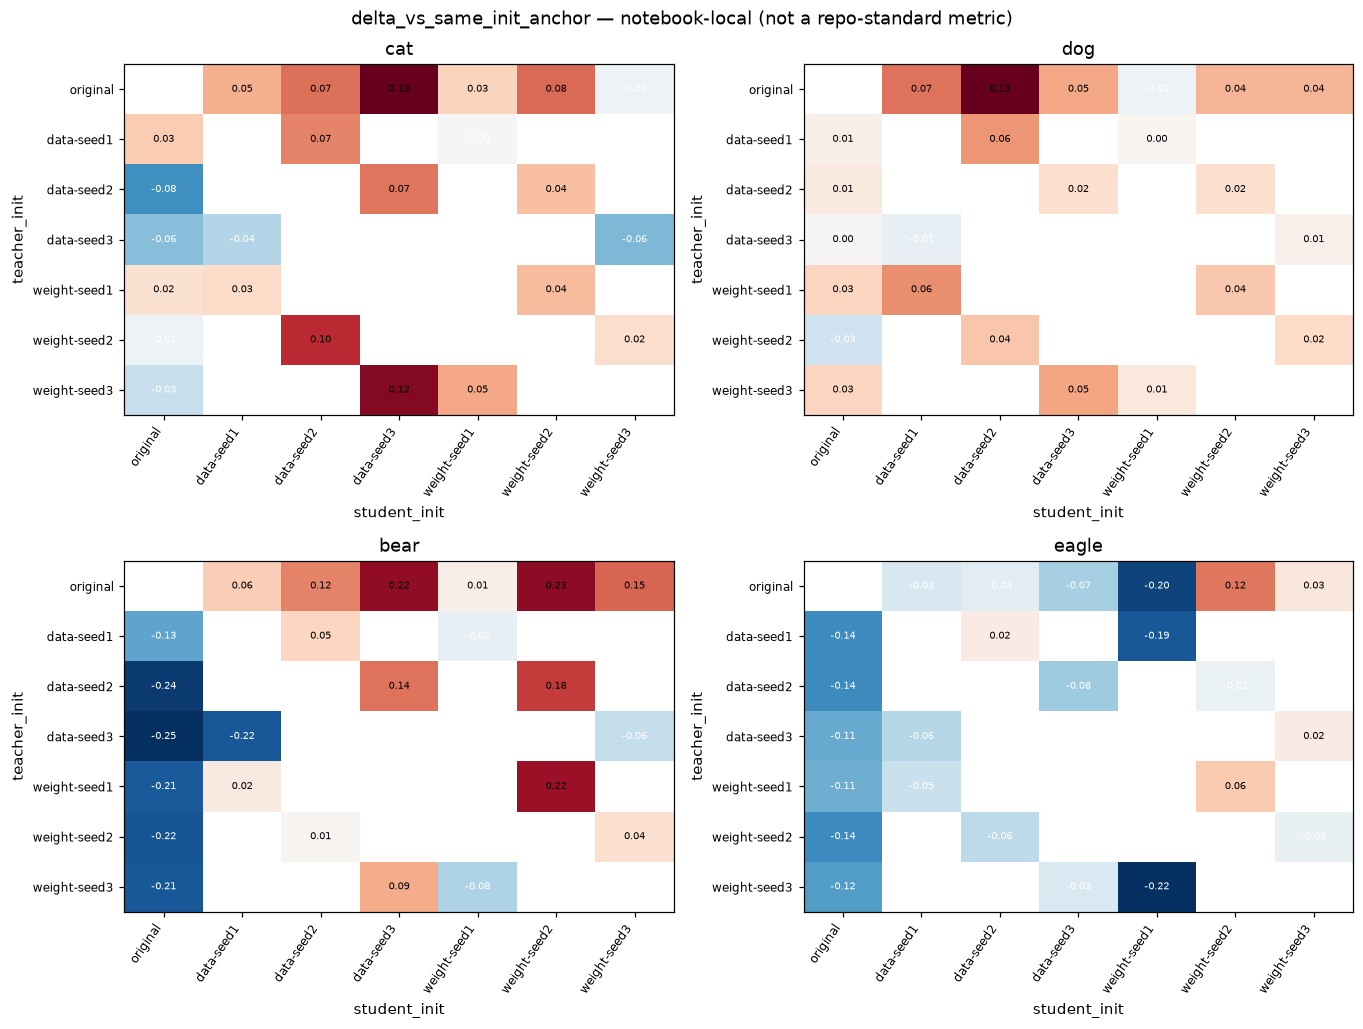

In [14]:
anchored = attach_same_init_anchor(pd_delta)
print_scope(anchored, "delta_vs_same_init_anchor (notebook-local)")
print(
    "Named metric: delta_vs_same_init_anchor. "
    "Analysis choice (checkpoint-ladder y precedent); not a repo-standard metric."
)
cross_only = anchored[~anchored["same_init_pair"]].copy()
display(
    cross_only.groupby("animal")["delta_vs_same_init_anchor"]
    .agg(["mean", "std", "count"])
    .reindex(list(ANIMALS))
)

fig, axes = animal_axes(figsize=(12.5, 9.5))
for ax, animal in zip(axes, ANIMALS):
    sub = cross_only[cross_only["animal"] == animal]
    g = (
        sub.pivot_table(
            index="teacher_base",
            columns="student_base",
            values="delta_vs_same_init_anchor",
            aggfunc="mean",
        )
        .reindex(index=BASE_ORDER, columns=BASE_ORDER)
    )
    aplots.annotated_heatmap(
        ax,
        g,
        cmap="RdBu_r",
        vmin=-float(np.nanmax(np.abs(g.to_numpy()))),
        vmax=float(np.nanmax(np.abs(g.to_numpy()))) if np.isfinite(g.to_numpy()).any() else 0.1,
        fmt="{:.2f}",
        origin="upper",
        empty_facecolor="#f4f4f4",
        mid=0.0,
        cell_fontsize=6.5,
    )
    ax.set_title(animal)
    ax.set_xlabel("student_init")
    ax.set_ylabel("teacher_init")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("delta_vs_same_init_anchor — notebook-local (not a repo-standard metric)")
plt.tight_layout()
plt.show()


## 10. Family breakdown

**What this measures.** Data-seed family versus weight-seed family as a
factor (pairings where both sides share a family), with pairing-cluster
CIs, plus `astats.family_interaction_fit` on
`Δ ~ 1[cross-init] + family + 1[cross-init]×family`. Family-swap and
seed-0-anchored pairings are shown descriptively but excluded from the
binary family fit. This is not an H1 verdict.


SCOPE: 48 configs | 4 animal(s) x 6 base model(s) | seeds pre-averaged | same-family pairings (data vs weight)


Family means (pairing-cluster CI):


,animal,family,mean,ci_lo,ci_hi,n_pairings,p_boot
0,cat,data,0.163949,0.120220,0.203231,6,0.0
1,cat,weight,0.181674,0.140795,0.222868,6,0.0
2,dog,data,0.113068,0.079728,0.143639,6,0.0
3,dog,weight,0.092197,0.072096,0.112298,6,0.0
4,bear,data,0.241719,0.168840,0.321863,6,0.0
5,bear,weight,0.274070,0.194297,0.348712,6,0.0
6,eagle,data,0.163556,0.112437,0.215110,6,0.0
7,eagle,weight,0.165645,0.114270,0.224328,6,0.0


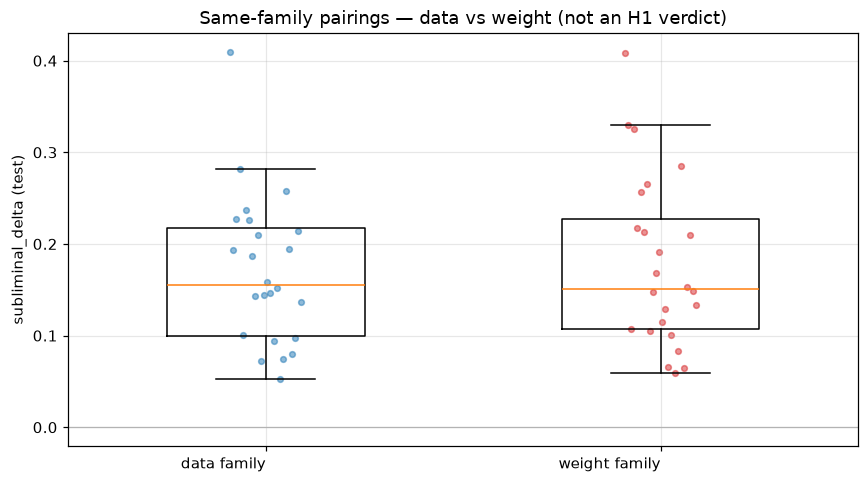

cat: interaction=0.006 CI[-0.125, 0.138] n=12 clusters=12
dog: interaction=0.002 CI[-0.087, 0.091] n=12 clusters=12
bear: interaction=0.068 CI[-0.187, 0.323] n=12 clusters=12
eagle: interaction=-0.019 CI[-0.188, 0.150] n=12 clusters=12
family_interaction_fit (d_trait = 1[cross-init]; family data=0 weight=1):


,animal,n_obs,n_clusters,intercept,d_trait_cross,d_trait_ci,family_weight,family_ci,interaction,interaction_ci
0,cat,12,12,0.147463,0.032973,"(-0.061871329206369896, 0.12781713109858422)",0.014490,"(-0.0922390791963503, 0.12121851342799145)",0.006469,"(-0.12499292501083506, 0.1379316094972052)"
1,dog,12,12,0.101612,0.022913,"(-0.05486583694391357, 0.10069204333055488)",-0.021795,"(-0.09145059470381944, 0.047860117200550306)",0.001848,"(-0.08734980614054397, 0.0910458502415788)"
2,bear,12,12,0.245865,-0.008293,"(-0.1910430177914395, 0.17445798876515312)",-0.001601,"(-0.24785226970962454, 0.24465033289834365)",0.067905,"(-0.18746612470204396, 0.3232758624429565)"
3,eagle,12,12,0.183929,-0.040746,"(-0.1593004246286986, 0.07780833274606969)",0.011623,"(-0.1248843753267448, 0.148129687322249)",-0.019068,"(-0.1876608300781729, 0.14952440802198536)"


Out of scope: do not read the interaction sign as an H1/H2 verdict. H1 would be weight_cyclic (DI∩SS) beating data_cyclic (SI∩DS); this fit is a family main-effect / cross-init interaction, not that contrast.


In [15]:
fam = pd_delta.copy()
fam["pairing_family"] = [
    pairing_family(s, t) for s, t in zip(fam["student_base"], fam["teacher_base"])
]
fam_bin = fam[fam["pairing_family"].isin(["data", "weight"])].copy()
print_scope(fam_bin, "same-family pairings (data vs weight)")

fam_ci_rows = []
for animal in ANIMALS:
    for fam_name in ("data", "weight"):
        vals = fam_bin.loc[
            (fam_bin["animal"] == animal) & (fam_bin["pairing_family"] == fam_name),
            "subliminal_delta",
        ]
        if vals.empty:
            continue
        est = pairing_cluster_ci(vals.values)
        fam_ci_rows.append(
            {
                "animal": animal,
                "family": fam_name,
                "mean": est.estimate,
                "ci_lo": est.ci_low,
                "ci_hi": est.ci_high,
                "n_pairings": int(vals.size),
                "p_boot": est.p_boot,
            }
        )
fam_ci = pd.DataFrame(fam_ci_rows)
print("Family means (pairing-cluster CI):")
display(fam_ci)

fig, ax = plt.subplots(figsize=(8.0, 4.5))
aplots.strip_box(
    ax,
    [
        fam_bin.loc[fam_bin["pairing_family"] == "data", "subliminal_delta"].to_numpy(),
        fam_bin.loc[fam_bin["pairing_family"] == "weight", "subliminal_delta"].to_numpy(),
    ],
    ["data family", "weight family"],
    colors=["C0", "C3"],
    zero_line=True,
    rotation=0,
)
ax.set_ylabel(f"subliminal_delta ({PRIMARY_SET})")
ax.set_title("Same-family pairings — data vs weight (not an H1 verdict)")
plt.tight_layout()
plt.show()

fit_rows = []
for animal in ANIMALS:
    sub = fam_bin[fam_bin["animal"] == animal]
    if sub["pairing_family"].nunique() < 2:
        print(f"{animal}: skip family_interaction_fit (need both families)")
        continue
    fit = astats.family_interaction_fit(
        sub["subliminal_delta"].to_numpy(),
        (~sub["same_init_pair"]).astype(float).to_numpy(),
        sub["pairing_family"].tolist(),
        sub["pairing"].tolist(),
    )
    fit_rows.append(
        {
            "animal": animal,
            "n_obs": fit.n_obs,
            "n_clusters": fit.n_clusters,
            "intercept": fit.intercept.estimate,
            "d_trait_cross": fit.d_trait.estimate,
            "d_trait_ci": (fit.d_trait.ci_low, fit.d_trait.ci_high),
            "family_weight": fit.family.estimate,
            "family_ci": (fit.family.ci_low, fit.family.ci_high),
            "interaction": fit.interaction.estimate,
            "interaction_ci": (fit.interaction.ci_low, fit.interaction.ci_high),
        }
    )
    print(
        f"{animal}: interaction={fit.interaction.estimate:.3f} "
        f"CI[{fit.interaction.ci_low:.3f}, {fit.interaction.ci_high:.3f}] "
        f"n={fit.n_obs} clusters={fit.n_clusters}"
    )
fam_fit = pd.DataFrame(fit_rows)
print("family_interaction_fit (d_trait = 1[cross-init]; family data=0 weight=1):")
display(fam_fit)
print(
    "Out of scope: do not read the interaction sign as an H1/H2 verdict. "
    "H1 would be weight_cyclic (DI∩SS) beating data_cyclic (SI∩DS); this fit "
    "is a family main-effect / cross-init interaction, not that contrast."
)


## 11. Direction asymmetry

**What this measures.** A→B versus B→A on pairings that exist in both
directions, per animal. These are **directed** pairings — do not treat
them as an undirected graph.


Undirected pairs present in both directions: 9
  (each is two directed pairings; do not collapse them.)
SCOPE: 36 configs | 4 animal(s) x 0 base model(s) | seeds pre-averaged | directed pairings with a reverse


,mean,std,count
animal,,,
cat,0.047938,0.050513,9
dog,0.047394,0.048472,9
bear,0.004485,0.169677,9
eagle,-0.008649,0.147196,9


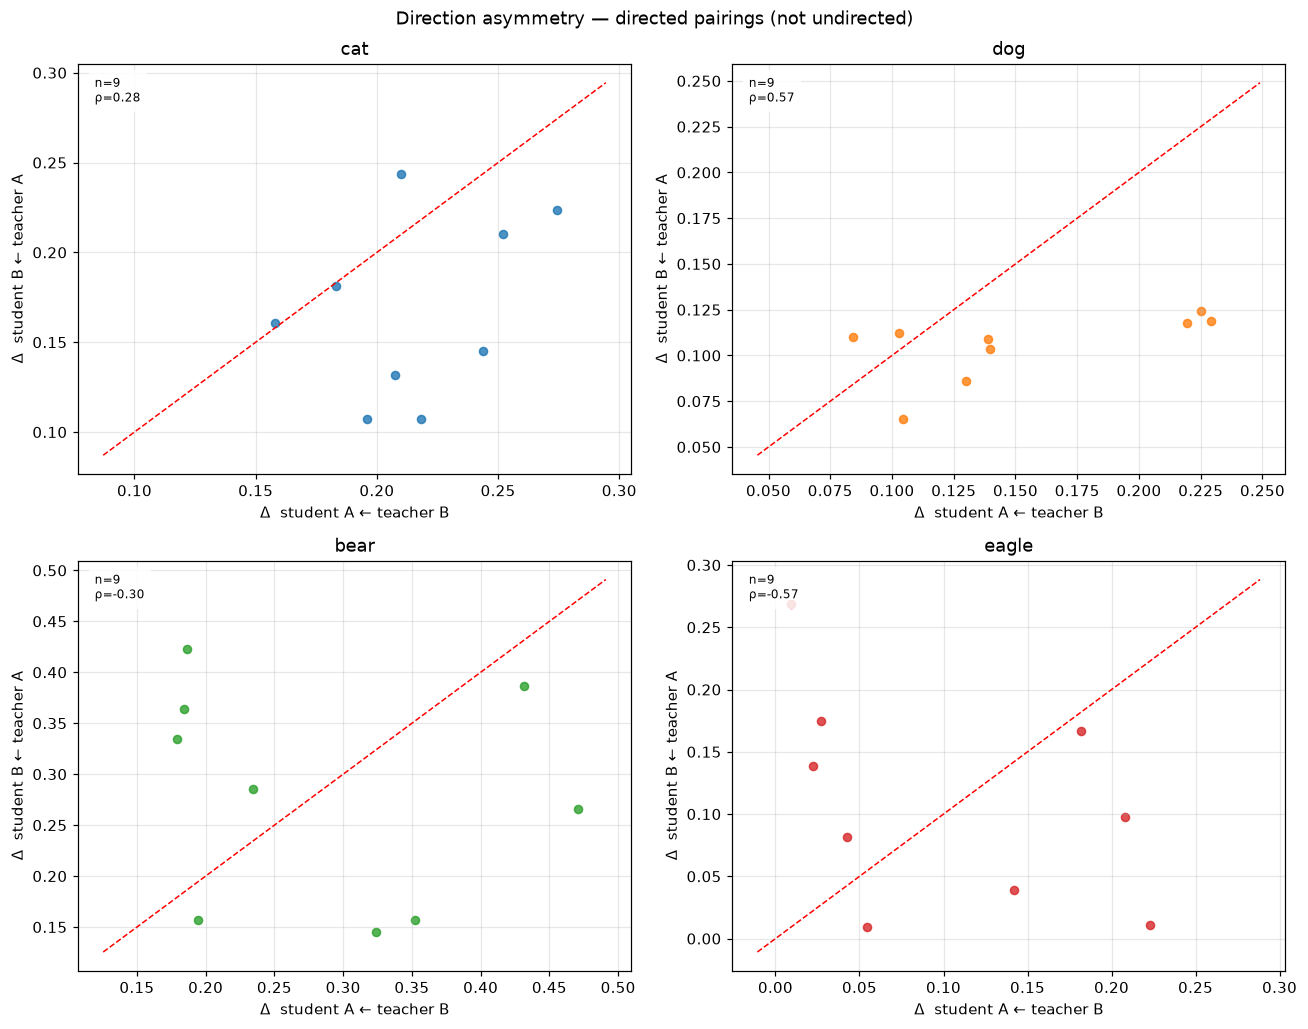

In [16]:
rev_pairs = []
have = {(s, t) for s, t in zip(pd_delta["student_base"], pd_delta["teacher_base"])}
for s, t in have:
    if s != t and (t, s) in have and (s, t) < (t, s):
        rev_pairs.append((s, t))
print(f"Undirected pairs present in both directions: {len(rev_pairs)}")
print("  (each is two directed pairings; do not collapse them.)")

asy_rows = []
for animal in ANIMALS:
    sub = pd_delta[pd_delta["animal"] == animal]
    by = sub.set_index("pairing")["subliminal_delta"]
    for s, t in rev_pairs:
        fwd = by.get(f"{s}|{t}")
        rev = by.get(f"{t}|{s}")
        if fwd is None or rev is None or (fwd != fwd) or (rev != rev):
            continue
        asy_rows.append(
            {
                "animal": animal,
                "a": s,
                "b": t,
                "delta_a_from_b": float(fwd),
                "delta_b_from_a": float(rev),
                "asymmetry": float(fwd) - float(rev),
            }
        )
asy = pd.DataFrame(asy_rows)
print_scope(asy, "directed pairings with a reverse")
display(asy.groupby("animal")["asymmetry"].agg(["mean", "std", "count"]).reindex(list(ANIMALS)))

fig, axes = animal_axes(figsize=(12.0, 9.5))
for ax, animal in zip(axes, ANIMALS):
    sub = asy[asy["animal"] == animal]
    aplots.identity_scatter(
        ax,
        sub,
        "delta_a_from_b",
        "delta_b_from_a",
        stat="spearman",
        diag_lim=(
            float(min(sub["delta_a_from_b"].min(), sub["delta_b_from_a"].min())) - 0.02,
            float(max(sub["delta_a_from_b"].max(), sub["delta_b_from_a"].max())) + 0.02,
        ) if len(sub) else (0.0, 1.0),
        color=ANIMAL_COLORS[animal],
        s=28,
        alpha=0.8,
        title_stats=True,
        textbox=True,
    )
    ax.set_title(animal)
    ax.set_xlabel("Δ  student A ← teacher B")
    ax.set_ylabel("Δ  student B ← teacher A")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("Direction asymmetry — directed pairings (not undirected)")
plt.tight_layout()
plt.show()


## 12. Seeds and power

**What this measures.** Nested variance components (pairing / teacher
ftseed / gseed) on the **8 headline pairings only**; leaf-bootstrap rank
stability of the corner ordering; and an explicit power contrast of
headline 3×3 versus extension 1×3. **Never pool the two tiers in a
single CI.**


In [17]:
head_seed = seed_delta[seed_delta["headline"]].dropna(subset=["subliminal_delta"])
print_scope(head_seed, "headline leaves only (8 pairings × animals × tfs × gseed)")
vc_h = astats.variance_components(
    head_seed["subliminal_delta"].to_numpy(),
    {
        "pairing": head_seed["pairing"].tolist(),
        "tfs": head_seed["teacher_ftseed"].astype(str).tolist(),
        "gseed": head_seed["gseed"].astype(str).tolist(),
    },
    order=("pairing", "tfs", "gseed"),
)
print("Headline nested VC (pairing → tfs → gseed):")
print({k: round(v, 4) for k, v in vc_h.fractions.items()}, "n_obs", vc_h.n_obs)

ext_seed = seed_delta[~seed_delta["headline"]].dropna(subset=["subliminal_delta"])
print(
    f"Extension leaves: {len(ext_seed)} (1 tfs × 3 gseed). "
    "Do not pool with headline 3×3 in one interval."
)
print(
    "Headline n per pairing (should be 3 tfs × 3 gseed × 1 animal-slice when split):",
    head_seed.groupby(["animal", "pairing"]).size().describe().to_dict(),
)

def rank_stability(
    leaf: pd.DataFrame, *, animal: str, n_boot: int = 1000, seed: int = BOOTSTRAP_SEED
) -> dict[str, Any]:
    """Bootstrap leaves: how often the observed corner order is preserved."""
    d = leaf[leaf["animal"] == animal].copy()
    obs = (
        d.groupby(["corner", "pairing"], dropna=False)["subliminal_delta"]
        .mean()
        .groupby("corner")
        .mean()
        .reindex(CORNER_ORDER)
    )
    obs_order = tuple(obs.sort_values(ascending=False).index.tolist())
    rng = np.random.default_rng(seed)
    groups = {
        (c, p): g["subliminal_delta"].to_numpy(dtype=float)
        for (c, p), g in d.groupby(["corner", "pairing"], dropna=False)
    }
    match = 0
    for _ in range(n_boot):
        cell_means = []
        for corner in CORNER_ORDER:
            pair_means = [
                float(rng.choice(vals, size=len(vals), replace=True).mean())
                for (c, _p), vals in groups.items()
                if c == corner and len(vals)
            ]
            cell_means.append(float(np.mean(pair_means)) if pair_means else np.nan)
        order = tuple(CORNER_ORDER[i] for i in np.argsort(-np.asarray(cell_means)))
        if order == obs_order:
            match += 1
    return {
        "animal": animal,
        "observed_order": obs_order,
        "frac_preserved": match / n_boot,
        "n_boot": n_boot,
    }


stab = pd.DataFrame(
    [rank_stability(head_seed, animal=a) for a in ANIMALS]
)
print("Headline leaf-bootstrap corner-rank stability (post-hoc):")
display(stab)

print("Headline vs extension pairing-cluster CIs are in §5 — do not concatenate them.")


SCOPE: 288 configs | 4 animal(s) x 6 base model(s) | seeds pre-averaged | headline leaves only (8 pairings × animals × tfs × gseed)
Headline nested VC (pairing → tfs → gseed):
{'pairing': 0.1823, 'tfs': 0.0121, 'gseed': 0.0034, 'residual': 0.8022} n_obs 288
Extension leaves: 276 (1 tfs × 3 gseed). Do not pool with headline 3×3 in one interval.
Headline n per pairing (should be 3 tfs × 3 gseed × 1 animal-slice when split): {'count': 32.0, 'mean': 9.0, 'std': 0.0, 'min': 9.0, '25%': 9.0, '50%': 9.0, '75%': 9.0, 'max': 9.0}


Headline leaf-bootstrap corner-rank stability (post-hoc):


,animal,observed_order,frac_preserved,n_boot
0,cat,"(diff_init_diff_stream, shared_init_shared_str...",0.684,1000
1,dog,"(diff_init_diff_stream, shared_init_shared_str...",0.995,1000
2,bear,"(diff_init_diff_stream, shared_init_shared_str...",0.489,1000
3,eagle,"(shared_init_shared_stream, diff_init_shared_s...",0.896,1000


Headline vs extension pairing-cluster CIs are in §5 — do not concatenate them.


## 13. Prompt-set generalization ladder

**What this measures.** Corner × prompt-set Δ, per animal. Prob-scored
sets and the sample-scored `storytelling` set are kept visually distinct.
`n_prompts` differs (storytelling 16, register 40, others 50). Storytelling
is the Cloud-parity OOD set and is new this campaign.


SCOPE: 868 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | Δ all prompt sets
Set scoring / n_prompts:


,scoring,n_prompts
set,,
test,prob,50
favorite,prob,50
dislike,prob,50
validation,prob,50
consensus,prob,50
register,prob,40
storytelling,sample,16


prob sets: ['test', 'favorite', 'dislike', 'validation', 'consensus', 'register'] sample sets: ['storytelling']


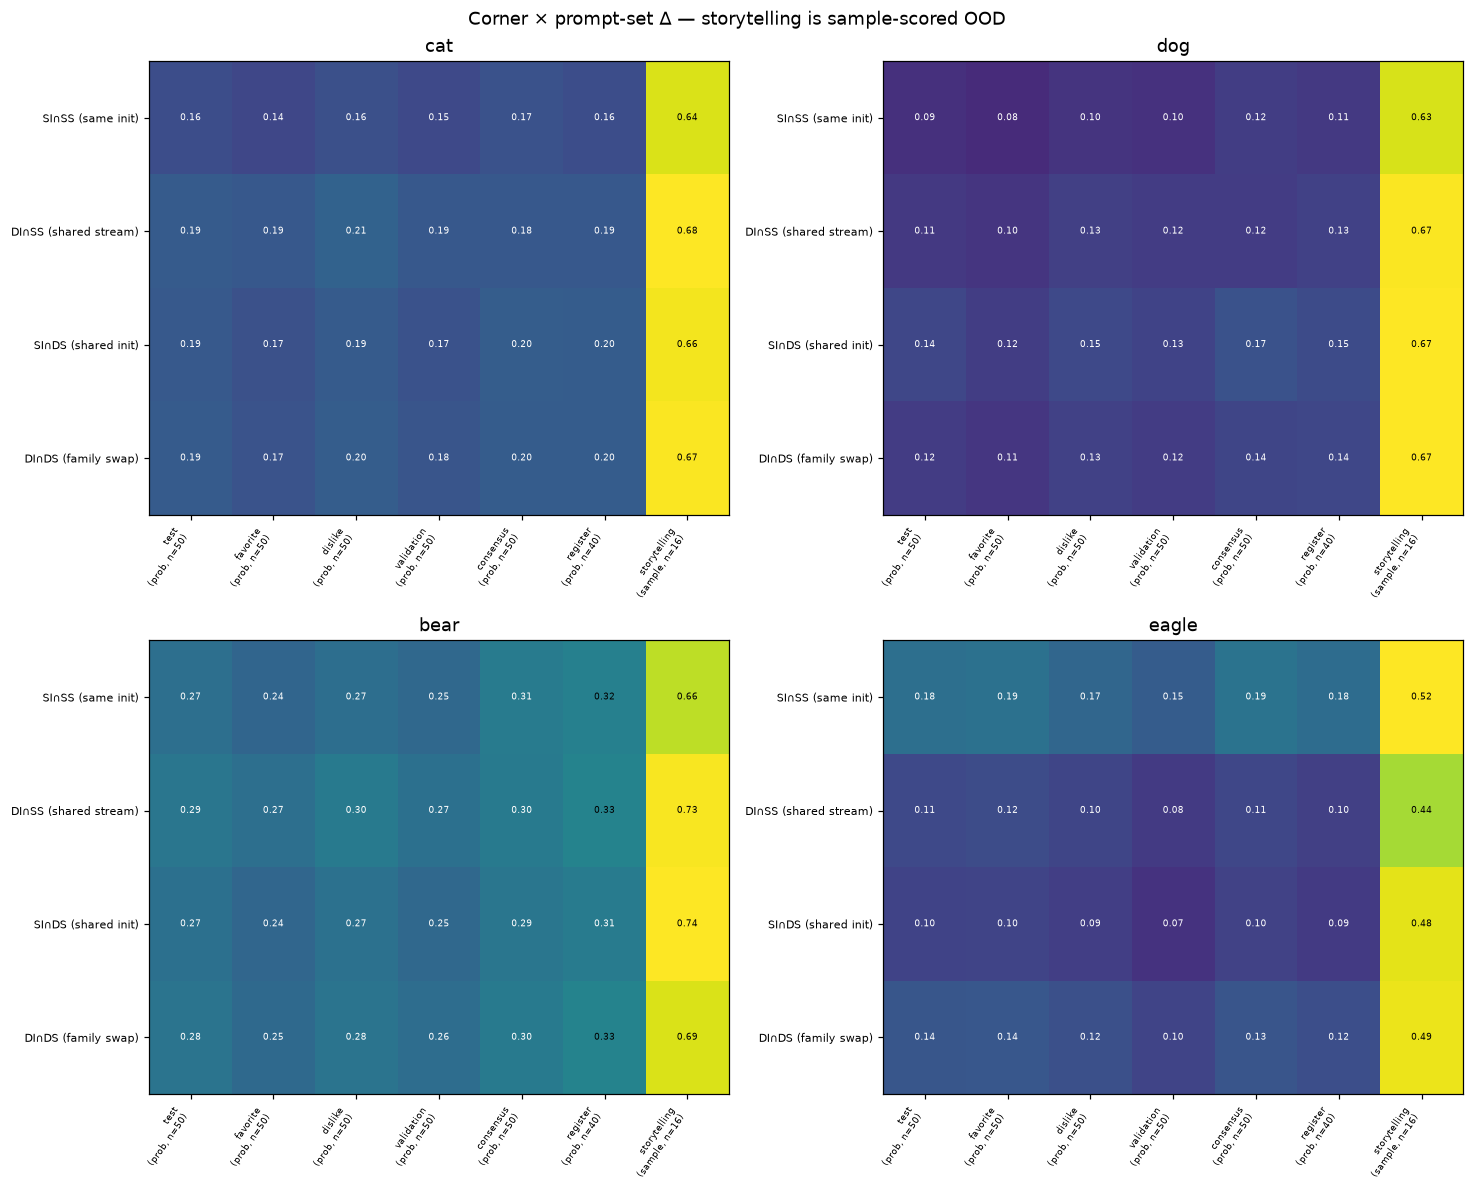

Storytelling vs test pairing Spearman:
  cat: ρ=0.39 p=0.0311 n=31
  dog: ρ=0.48 p=0.00651 n=31
  bear: ρ=0.72 p=5.3e-06 n=31
  eagle: ρ=0.72 p=5.69e-06 n=31


In [18]:
delta_all = annotate_pairing(delta)
print_scope(delta_all, "Δ all prompt sets")
set_meta = (
    pref[~pref.is_control]
    .drop_duplicates("set")[["set", "scoring", "n_prompts"]]
    .set_index("set")
)
print("Set scoring / n_prompts:")
display(set_meta.reindex(list(PROMPT_SETS)))

prob_sets = [s for s in PROMPT_SETS if set_meta.loc[s, "scoring"] == "prob"]
sample_sets = [s for s in PROMPT_SETS if set_meta.loc[s, "scoring"] == "sample"]
print("prob sets:", prob_sets, "sample sets:", sample_sets)

fig, axes = animal_axes(figsize=(13.5, 11.0))
for ax, animal in zip(axes, ANIMALS):
    sub = delta_all[delta_all["animal"] == animal]
    g = (
        sub.pivot_table(
            index="corner",
            columns="set",
            values="subliminal_delta",
            aggfunc="mean",
        )
        .reindex(index=CORNER_ORDER, columns=list(PROMPT_SETS))
    )
    aplots.annotated_heatmap(
        ax,
        g,
        cmap="viridis",
        vmin=0.0,
        vmax=max(float(np.nanpercentile(g.to_numpy(), 98)), 0.05),
        fmt="{:.2f}",
        origin="upper",
        cell_fontsize=6.0,
    )
    ax.set_title(animal)
    ax.set_yticklabels([CORNER_SHORT[c] for c in CORNER_ORDER], fontsize=7)
    ax.set_xticklabels(
        [
            f"{s}\n({set_meta.loc[s, 'scoring']}, n={int(set_meta.loc[s, 'n_prompts'])})"
            for s in PROMPT_SETS
        ],
        fontsize=6,
    )
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("Corner × prompt-set Δ — storytelling is sample-scored OOD")
plt.tight_layout()
plt.show()

# Storytelling vs test concordance (pairing-level).
st_vs_test = (
    delta_all[delta_all["set"].isin(["test", "storytelling"])]
    .pivot_table(
        index=["animal", "pairing"],
        columns="set",
        values="subliminal_delta",
        aggfunc="mean",
    )
    .reset_index()
    .dropna()
)
print("Storytelling vs test pairing Spearman:")
for animal in ANIMALS:
    sub = st_vs_test[st_vs_test["animal"] == animal]
    rho, pval = spearmanr(sub["test"], sub["storytelling"])
    print(f"  {animal}: ρ={rho:.2f} p={pval:.3g} n={len(sub)}")


## 14. Specificity and capability

**What this measures.** Forced-choice target share by corner; a 4×4
off-target matrix over the campaign animals (does a cat student leak
toward dog / bear / eagle?); Pile PPL ratio with a finite mask; and
lm-eval on the headline treat + control dirs only. Extension dirs have
no `benchmarks` key **by design** — never impute, never assert absence
as a bug. The earlier campaign had no usable benchmark data.


SCOPE: 188 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | forced-choice target share (treat)
FC target_share by corner (mean over pairings):


corner,shared_init_shared_stream,diff_init_shared_stream,shared_init_diff_stream,diff_init_diff_stream
animal,,,,
cat,0.827970,0.845375,0.864083,0.843144
dog,0.798100,0.824025,0.856514,0.855151
bear,0.917954,0.926791,0.921241,0.937260
eagle,0.838843,0.718415,0.677949,0.738901


4×4 off-target matrix (mean candidate_share; diagonal = target):


candidate,cat,dog,bear,eagle
animal,,,,
cat,0.846001,0.079264,0.008687,0.000846
dog,0.059829,0.833566,0.015061,0.001918
bear,0.007360,0.025227,0.925415,0.001442
eagle,0.013957,0.044931,0.027688,0.739766


SCOPE: 752 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | 4×4 campaign-animal FC shares


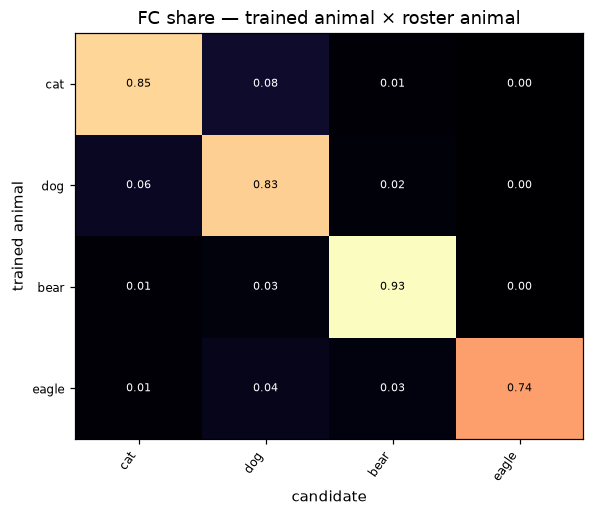

PPL ratio finite mask: 188/188 treat configs range 1.50–2.81
SCOPE: 188 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | finite PPL ratios
bench_* columns present: ['bench_lambada_openai_sample_len', 'bench_lambada_openai_perplexity', 'bench_lambada_openai_acc', 'bench_arc_easy_sample_len', 'bench_arc_easy_acc', 'bench_arc_easy_acc_norm', 'bench_sciq_sample_len', 'bench_sciq_acc', 'bench_sciq_acc_norm']
lm-eval coverage: headline treat 96/96; extension 0/92 (absent by design — not a gap); controls 28/28
Headline treat lm-eval means:


,mean
bench_lambada_openai_sample_len,5153.000000
bench_lambada_openai_perplexity,808.965331
bench_lambada_openai_acc,0.083040
bench_arc_easy_sample_len,2376.000000
bench_arc_easy_acc,0.379774
bench_arc_easy_acc_norm,0.349550
bench_sciq_sample_len,1000.000000
bench_sciq_acc,0.580378
bench_sciq_acc_norm,0.515017


Control lm-eval means:


,mean
bench_lambada_openai_sample_len,5153.000000
bench_lambada_openai_perplexity,177.024428
bench_lambada_openai_acc,0.183393
bench_arc_easy_sample_len,2376.000000
bench_arc_easy_acc,0.419613
bench_arc_easy_acc_norm,0.379239
bench_sciq_sample_len,1000.000000
bench_sciq_acc,0.682274
bench_sciq_acc_norm,0.589512


Base lm-eval means (from treat headline rows):


,mean
base_lambada_openai_sample_len,5153.000000
base_lambada_openai_perplexity,34.494420
base_lambada_openai_acc,0.355084
base_arc_easy_sample_len,2376.000000
base_arc_easy_acc,0.436448
base_arc_easy_acc_norm,0.393308
base_sciq_sample_len,1000.000000
base_sciq_acc,0.749375
base_sciq_acc_norm,0.669625


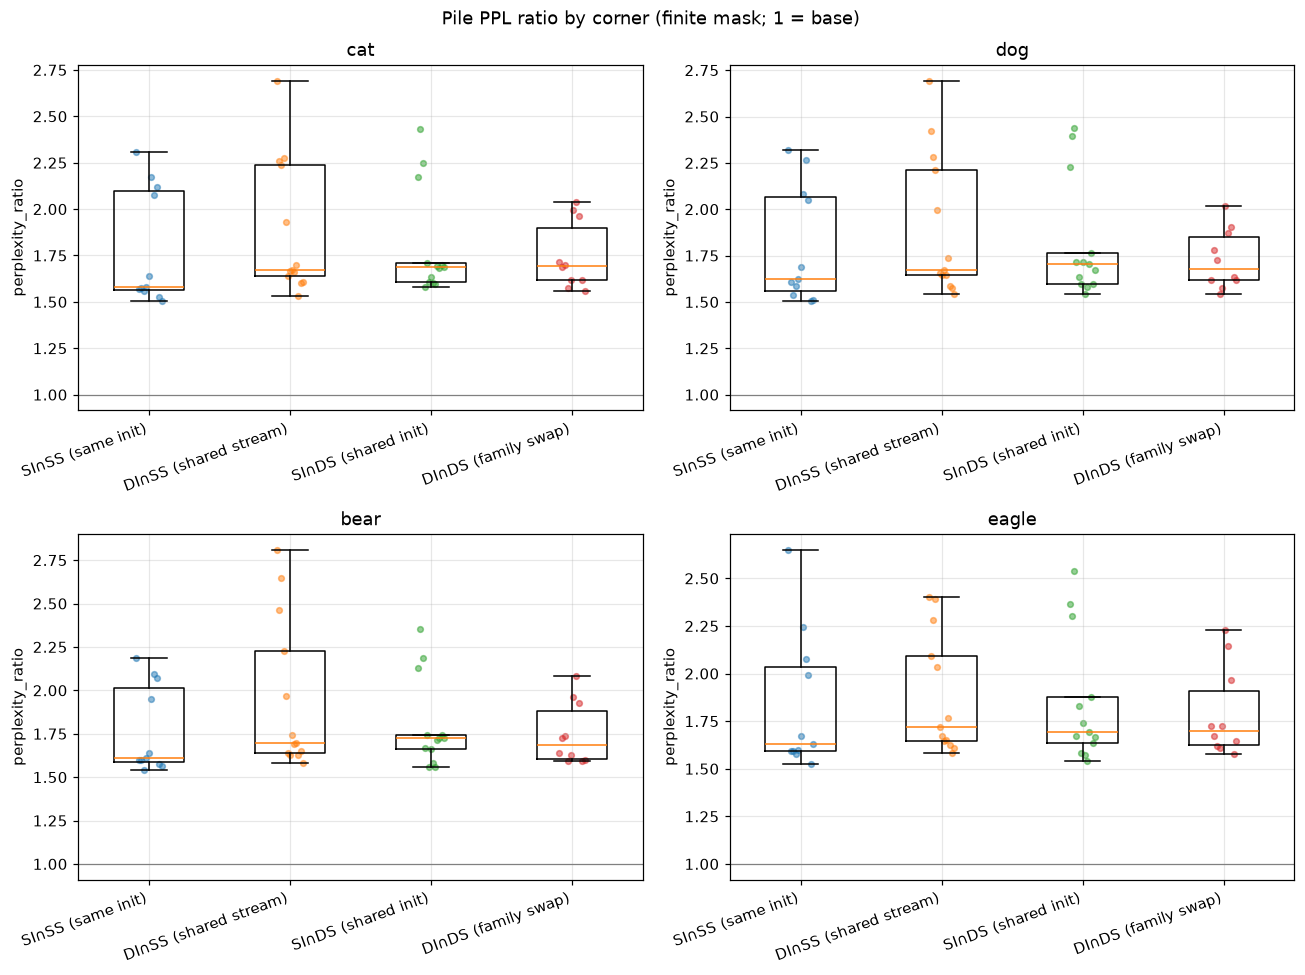

In [19]:
fc_t = annotate_pairing(fc[~fc["is_control"]].copy())
fc_target = fc_t[fc_t["is_target"]].copy()
print_scope(fc_target, "forced-choice target share (treat)")
print("FC target_share by corner (mean over pairings):")
display(
    fc_target.groupby(["animal", "corner"])["target_share_mean"]
    .mean()
    .unstack()
    .reindex(index=list(ANIMALS), columns=CORNER_ORDER)
)

# 4×4 off-target among campaign animals.
off = fc_t[fc_t["candidate"].isin(ANIMALS)].copy()
leak = (
    off.groupby(["animal", "candidate"], dropna=False)["candidate_share"]
    .mean()
    .unstack()
    .reindex(index=list(ANIMALS), columns=list(ANIMALS))
)
print("4×4 off-target matrix (mean candidate_share; diagonal = target):")
display(leak)
print_scope(off, "4×4 campaign-animal FC shares")
fig, ax = plt.subplots(figsize=(5.5, 4.8))
aplots.annotated_heatmap(
    ax, leak, cmap="magma", vmin=0.0, vmax=max(float(np.nanmax(leak.to_numpy())), 0.1),
    fmt="{:.2f}", origin="upper",
)
ax.set_title("FC share — trained animal × roster animal")
ax.set_xlabel("candidate")
ax.set_ylabel("trained animal")
plt.tight_layout()
plt.show()

# Capability: PPL + optional benchmarks.
cap_ann = annotate_pairing(cap[~cap["is_control"]].copy())
cap_ctrl = cap[cap["is_control"]].copy()
finite = cap_ann[np.isfinite(cap_ann["perplexity_ratio"])].copy()
print(
    f"PPL ratio finite mask: {len(finite)}/{len(cap_ann)} treat configs "
    f"range {finite.perplexity_ratio.min():.2f}–{finite.perplexity_ratio.max():.2f}"
)
print_scope(finite, "finite PPL ratios")

bench_cols = [c for c in cap.columns if c.startswith("bench_")]
print("bench_* columns present:", bench_cols)
cap_ann["has_benchmarks"] = (
    cap_ann[bench_cols].notna().any(axis=1) if bench_cols else False
)
cap_ctrl["has_benchmarks"] = (
    cap_ctrl[bench_cols].notna().any(axis=1) if bench_cols else False
)
n_head_bench = int(cap_ann.loc[cap_ann["headline"], "has_benchmarks"].sum())
n_head = int(cap_ann["headline"].sum())
n_ext_bench = int(cap_ann.loc[~cap_ann["headline"], "has_benchmarks"].sum())
n_ext = int((~cap_ann["headline"]).sum())
n_ctrl_bench = int(cap_ctrl["has_benchmarks"].sum())
print(
    f"lm-eval coverage: headline treat {n_head_bench}/{n_head}; "
    f"extension {n_ext_bench}/{n_ext} (absent by design — not a gap); "
    f"controls {n_ctrl_bench}/{len(cap_ctrl)}"
)
assert n_ext_bench == 0, "extension dirs must not have imputed benchmarks"

if bench_cols:
    bench_h = cap_ann[cap_ann["headline"]].copy()
    print("Headline treat lm-eval means:")
    display(bench_h[bench_cols].mean().to_frame("mean"))
    print("Control lm-eval means:")
    display(cap_ctrl[bench_cols].mean().to_frame("mean"))
    print("Base lm-eval means (from treat headline rows):")
    base_cols = [c for c in cap.columns if c.startswith("base_") and any(t in c for t in ("arc_easy", "lambada", "sciq"))]
    if base_cols:
        display(bench_h[base_cols].mean().to_frame("mean"))

fig, axes = animal_axes(figsize=(12.0, 9.0))
for ax, animal in zip(axes, ANIMALS):
    sub = finite[finite["animal"] == animal]
    aplots.strip_box(
        ax,
        groups_for_strip(sub, "corner", "perplexity_ratio", CORNER_ORDER),
        [CORNER_SHORT[c] for c in CORNER_ORDER],
        rotation=20,
    )
    ax.axhline(1.0, color="0.5", lw=0.8)
    ax.set_title(animal)
    ax.set_ylabel("perplexity_ratio")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("Pile PPL ratio by corner (finite mask; 1 = base)")
plt.tight_layout()
plt.show()


## 15. Probe trajectories by corner

**What this measures.** In-training `p_target` after **deduplicating**
resume-append rows by `(run_dir, step)`. Median ± IQR bands per corner,
per animal. Divergence QC lists every diverged leaf; the sensitivity
check drops **all** of them (not just the first). Step 0 is present
(baseline at init). Probe metrics are not eval-grade.


Loading probe trajectories (expensive) ...


  probes: 48175 rows in 2.4s
Dedup by (run_dir, step) keep=last: 17072 → 16848 rows; leaves with duplicate steps: 32
SCOPE: 14664 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | deduped Stage B probes
Duplicate-row leaves (extra rows before dedup): 32


Diverged treat leaves: 1


,animal,pairing,run_dir,gseed
520,bear,original|weight-seed3,/mnt/ssd-3/soar-subliminal/vishesh/subliminal_...,2


SCOPE: 3666 configs | 1 animal(s) x 7 base model(s) | seeds pre-averaged | probe bands cat ~diverged
SCOPE: 3666 configs | 1 animal(s) x 7 base model(s) | seeds pre-averaged | probe bands dog ~diverged
SCOPE: 3640 configs | 1 animal(s) x 7 base model(s) | seeds pre-averaged | probe bands bear ~diverged


SCOPE: 3666 configs | 1 animal(s) x 7 base model(s) | seeds pre-averaged | probe bands eagle ~diverged


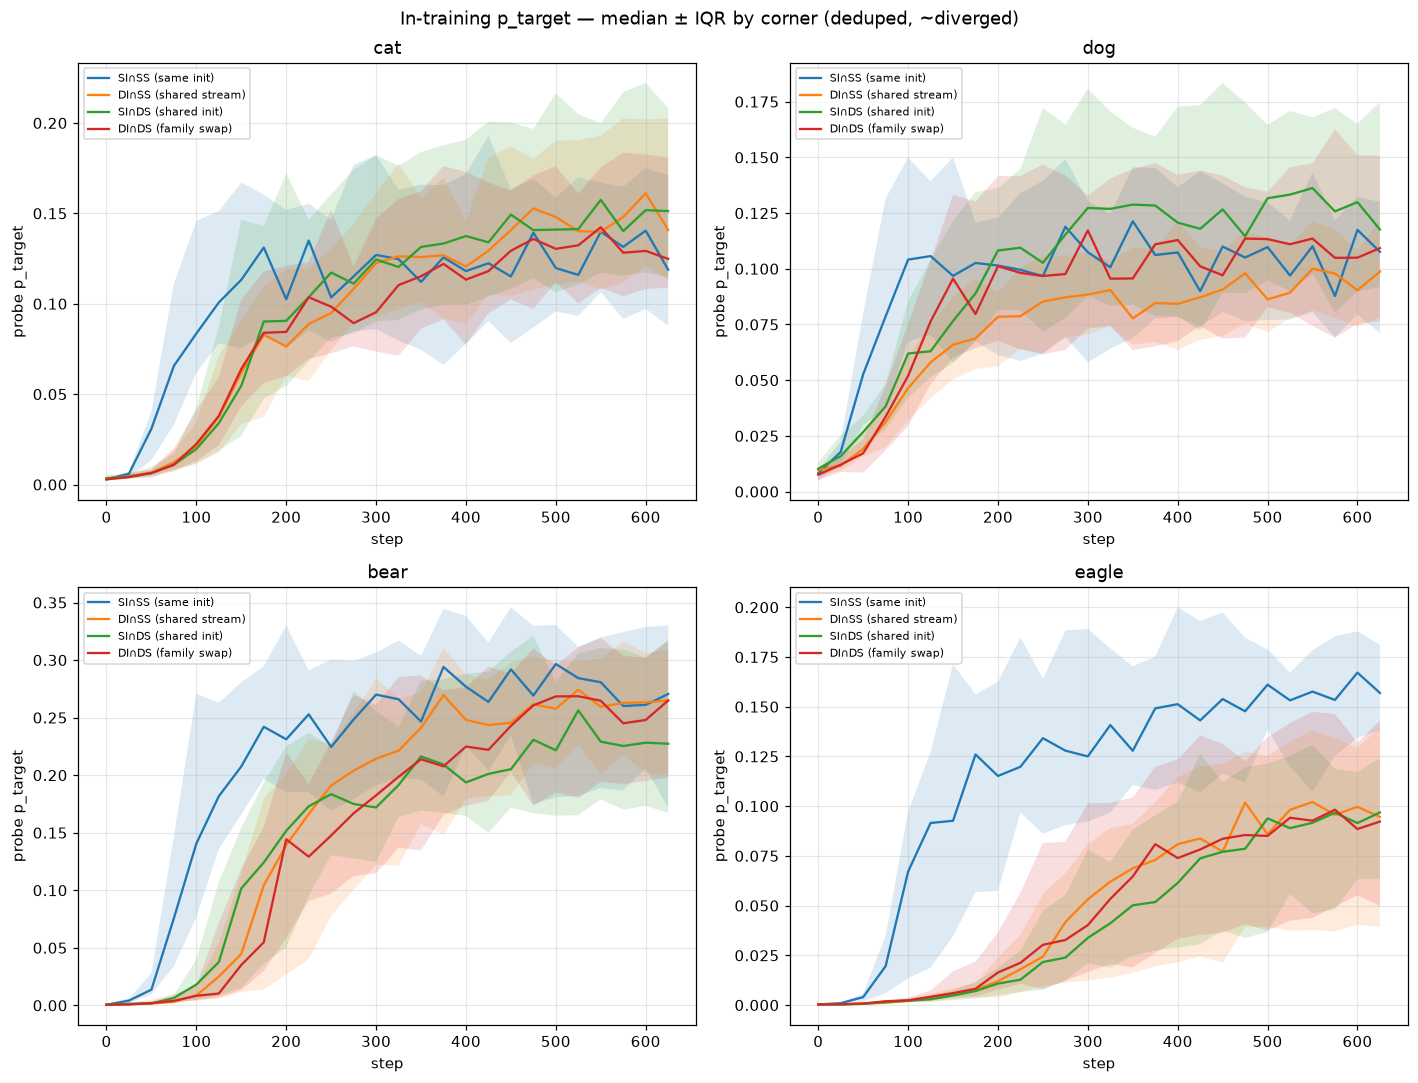

Sensitivity (end-of-run p_target mean after dropping ALL diverged leaves): keep-non-diverged-rows=0.1566 drop-all-diverged-leaves=0.1566 n_dropped_leaves=1
End-of-run vs peak (non-diverged treat):
  eor p_target mean 0.15655168564276137
  peak p_target mean 0.1985191541357518
Step-0 present: True


In [20]:
print("Loading probe trajectories (expensive) ...", flush=True)
t0 = time.perf_counter()
probes_all = load_gkd_probe_trajectories(OUTPUT_ROOT, SUBDIR)
print(f"  probes: {len(probes_all)} rows in {time.perf_counter() - t0:.1f}s")
probes = probes_all[probes_all["gkd_tag"] == FROZEN].copy()
n_before = len(probes)
n_dup_leaves = int(
    probes.groupby("run_dir")["step"]
    .apply(lambda s: s.duplicated().any())
    .sum()
)
probes = dedup_probe_steps(probes)
print(
    f"Dedup by (run_dir, step) keep=last: {n_before} → {len(probes)} rows; "
    f"leaves with duplicate steps: {n_dup_leaves}"
)
probes = annotate_pairing(probes)
treat_pr = probes[~probes["is_control"]].copy()
print_scope(treat_pr, "deduped Stage B probes")

dup_heavy = (
    probes_all[probes_all["gkd_tag"] == FROZEN]
    .groupby("run_dir")["step"]
    .apply(lambda s: int(s.duplicated().sum()))
)
print("Duplicate-row leaves (extra rows before dedup):", int((dup_heavy > 0).sum()))

div_leaves = (
    treat_pr.loc[treat_pr["diverged"], ["animal", "pairing", "run_dir", "gseed"]]
    .drop_duplicates("run_dir")
)
print(f"Diverged treat leaves: {len(div_leaves)}")
if not div_leaves.empty:
    display(div_leaves)

# Median ± IQR by corner, per animal (non-diverged).
clean = treat_pr[~treat_pr["diverged"]].copy()
fig, axes = animal_axes(figsize=(13.0, 10.0))
for ax, animal in zip(axes, ANIMALS):
    sub = clean[clean["animal"] == animal]
    print_scope(sub, f"probe bands {animal} ~diverged")
    for corner in CORNER_ORDER:
        g = sub[sub["corner"] == corner]
        if g.empty:
            continue
        band = g.groupby("step")["p_target"].agg(
            med="median",
            lo=lambda s: s.quantile(0.25),
            hi=lambda s: s.quantile(0.75),
        )
        ax.plot(band.index, band["med"], label=CORNER_SHORT[corner], lw=1.5)
        ax.fill_between(band.index, band["lo"], band["hi"], alpha=0.15)
    ax.set_title(animal)
    ax.set_xlabel("step")
    ax.set_ylabel("probe p_target")
    ax.legend(fontsize=7)
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("In-training p_target — median ± IQR by corner (deduped, ~diverged)")
plt.tight_layout()
plt.show()

# Sensitivity: drop ALL diverged leaves.
if not div_leaves.empty:
    dropped = treat_pr[~treat_pr["run_dir"].isin(set(div_leaves["run_dir"]))]
    eor_all = end_of_run_probes(treat_pr[~treat_pr["diverged"]])
    eor_drop = end_of_run_probes(dropped[~dropped["diverged"]])
    print(
        "Sensitivity (end-of-run p_target mean after dropping ALL diverged leaves): "
        f"keep-non-diverged-rows={eor_all.p_target.mean():.4f} "
        f"drop-all-diverged-leaves={eor_drop.p_target.mean():.4f} "
        f"n_dropped_leaves={len(div_leaves)}"
    )
else:
    print("No diverged leaves — sensitivity is a no-op.")

eor = end_of_run_probes(clean)
print("End-of-run vs peak (non-diverged treat):")
print("  eor p_target mean", float(eor["p_target"].mean()))
print("  peak p_target mean", float(peak_probes(clean)["p_target"].mean()))
print("Step-0 present:", 0 in set(treat_pr["step"].dropna().astype(int)))


## 16. Optimization / loss-matching

**What this measures.** Assert `n_train_steps` and `n_train_prompts` on
every Stage B leaf, then `final_train_loss` by corner and end-step
`fwd_kl` / `rev_kl` / `student_entropy` from trainer logs.


SCOPE: 564 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | train manifests, treat
n_train_steps unique: [np.int64(625)]
n_train_prompts unique: [np.int64(20000)]
final_train_loss by corner:


corner,shared_init_shared_stream,diff_init_shared_stream,shared_init_diff_stream,diff_init_diff_stream
animal,,,,
cat,0.542422,0.964966,0.879491,0.850893
dog,0.543721,0.981573,0.875374,0.836797
bear,0.542460,0.992719,0.878338,0.855082
eagle,0.553716,0.965453,0.879490,0.853896


Loading trainer logs ...


  logs: 114966 rows in 2.8s


SCOPE: 564 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | end-step trainer scalars
End-step GKD monitors by corner:


,fwd_kl,rev_kl,student_entropy,loss
corner,,,,
shared_init_shared_stream,0.551863,0.474296,2.650832,0.474295
diff_init_shared_stream,1.058343,0.903636,2.636710,0.903638
shared_init_diff_stream,0.944041,0.805245,2.684602,0.805244
diff_init_diff_stream,0.918566,0.785825,2.680438,0.785829


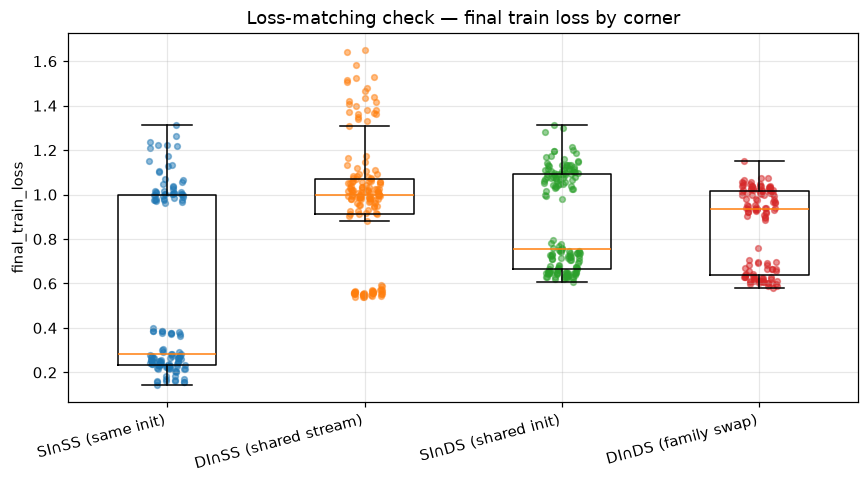

In [21]:
man_t = annotate_pairing(manifests[~manifests["is_control"]].copy())
print_scope(man_t, "train manifests, treat")
print("n_train_steps unique:", sorted(man_t["n_train_steps"].dropna().unique()))
print("n_train_prompts unique:", sorted(man_t["n_train_prompts"].dropna().unique()))
assert set(man_t["n_train_steps"].dropna().astype(int).unique()) == {625}
assert set(man_t["n_train_prompts"].dropna().astype(int).unique()) == {20000}
print("final_train_loss by corner:")
display(
    man_t.groupby(["animal", "corner"])["final_train_loss"]
    .mean()
    .unstack()
    .reindex(index=list(ANIMALS), columns=CORNER_ORDER)
)

print("Loading trainer logs ...", flush=True)
t0 = time.perf_counter()
logs_all = load_gkd_training_logs(OUTPUT_ROOT, SUBDIR)
print(f"  logs: {len(logs_all)} rows in {time.perf_counter() - t0:.1f}s")
logs = annotate_pairing(logs_all[logs_all["gkd_tag"] == FROZEN].copy())
logs_t = logs[~logs["is_control"]].copy()
end_logs = logs_t.sort_values("step").groupby("run_dir", as_index=False).tail(1)
print_scope(end_logs, "end-step trainer scalars")
print("End-step GKD monitors by corner:")
display(
    end_logs.groupby("corner")[["fwd_kl", "rev_kl", "student_entropy", "loss"]]
    .mean()
    .reindex(CORNER_ORDER)
)

fig, ax = plt.subplots(figsize=(8.0, 4.5))
aplots.strip_box(
    ax,
    groups_for_strip(man_t, "corner", "final_train_loss", CORNER_ORDER),
    [CORNER_SHORT[c] for c in CORNER_ORDER],
    rotation=15,
)
ax.set_ylabel("final_train_loss")
ax.set_title("Loss-matching check — final train loss by corner")
plt.tight_layout()
plt.show()


## 17. Behavioural leakage telemetry

**What this measures.** `flagged_rate` from `rollouts_summary.json` and
`mention_rate` from trainer logs. These are **telemetry, not trait
metrics**. Spearman against pairing Δ is descriptive only. Does **not**
load `rollouts_sample.jsonl`.


SCOPE: 564 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | rollouts_summary telemetry (not a trait metric)
flagged_rate by animal:


,mean,max,count
animal,,,
cat,0.159948,0.26985,141
dog,0.185777,0.27950,141
bear,0.164487,0.24695,141
eagle,0.134871,0.25580,141


Spearman telemetry vs Δ (descriptive, not a trait claim):
  cat flagged_rate: ρ=0.01 p=0.943 n=31
  cat mention_rate_mean: ρ=0.01 p=0.943 n=31
  dog flagged_rate: ρ=-0.12 p=0.53 n=31
  dog mention_rate_mean: ρ=-0.12 p=0.53 n=31
  bear flagged_rate: ρ=0.30 p=0.0954 n=31
  bear mention_rate_mean: ρ=0.30 p=0.0954 n=31
  eagle flagged_rate: ρ=0.58 p=0.000708 n=31
  eagle mention_rate_mean: ρ=0.58 p=0.000589 n=31


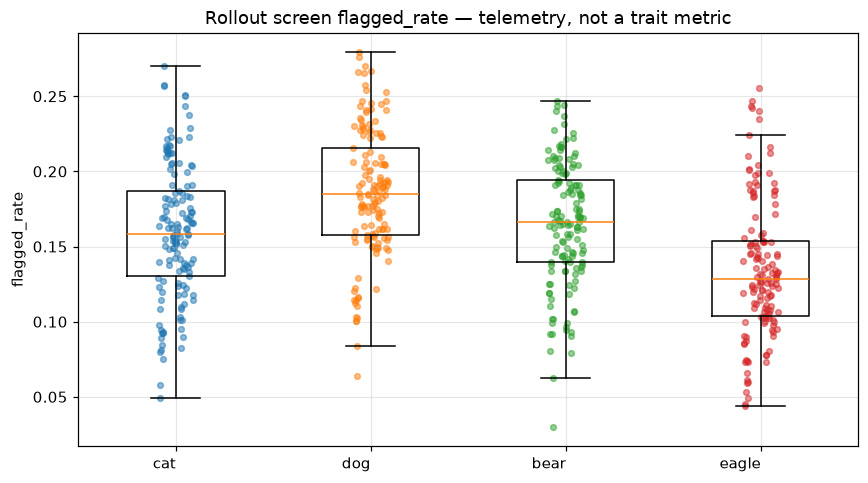

In [22]:
roll_rows: list[dict[str, Any]] = []
for path in sorted(TREE.glob(f"*/*/*/{FROZEN}/gseed*/rollouts_summary.json")):
    if path.relative_to(TREE).parts[0] == "controls":
        continue
    leaf = path.parent
    doc = json.loads(path.read_text())
    roll_rows.append(
        {
            "animal": leaf.parent.parent.parent.parent.name,
            "model": leaf.parent.parent.parent.name,
            "teacher_tag": leaf.parent.parent.name,
            "teacher_base_label": parse_teacher_tag(leaf.parent.parent.name)[
                "teacher_base_label"
            ],
            "gkd_tag": FROZEN,
            "gseed": int(leaf.name.removeprefix("gseed")),
            "is_control": False,
            "flagged_rate": doc.get("flagged_rate"),
            "n_flagged": doc.get("n_flagged"),
            "n_rows_screened": doc.get("n_rows_screened"),
            "run_dir": str(leaf),
        }
    )
roll = annotate_pairing(pd.DataFrame(roll_rows))
print_scope(roll, "rollouts_summary telemetry (not a trait metric)")
print("flagged_rate by animal:")
display(roll.groupby("animal")["flagged_rate"].agg(["mean", "max", "count"]).reindex(list(ANIMALS)))

ment = (
    logs_t.groupby(["animal", "student_base", "teacher_base"], dropna=False)["mention_rate"]
    .mean()
    .reset_index()
    .rename(columns={"mention_rate": "mention_rate_mean"})
)
tel = pd_delta.merge(ment, on=["animal", "student_base", "teacher_base"], how="left")
roll_pair = (
    roll.groupby(["animal", "student_base", "teacher_base"], dropna=False)["flagged_rate"]
    .mean()
    .reset_index()
)
tel = tel.merge(roll_pair, on=["animal", "student_base", "teacher_base"], how="left")
print("Spearman telemetry vs Δ (descriptive, not a trait claim):")
for animal in ANIMALS:
    sub = tel[tel["animal"] == animal]
    for col in ("flagged_rate", "mention_rate_mean"):
        xy = sub[[col, "subliminal_delta"]].dropna()
        if len(xy) < 3:
            print(f"  {animal} {col}: n={len(xy)} skip")
            continue
        rho, pval = spearmanr(xy[col], xy["subliminal_delta"])
        print(f"  {animal} {col}: ρ={rho:.2f} p={pval:.3g} n={len(xy)}")

fig, ax = plt.subplots(figsize=(8.0, 4.5))
aplots.strip_box(
    ax,
    groups_for_strip(roll, "animal", "flagged_rate", ANIMALS),
    list(ANIMALS),
    colors=[ANIMAL_COLORS[a] for a in ANIMALS],
    rotation=0,
)
ax.set_ylabel("flagged_rate")
ax.set_title("Rollout screen flagged_rate — telemetry, not a trait metric")
plt.tight_layout()
plt.show()


## 18. Concordance with the earlier 2-animal Stage B run

**What this measures.** Pairing-level Spearman on the cat/dog overlap
against `gkd_students/20260727_slbreadth_160m` (same grammar, same frozen
tag). Schema drift is listed explicitly. Guarded: if that tree is
missing, print a note and skip. Do not use `cats_wide_run`.


slbreadth tree: /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260727_slbreadth_160m exists: True


slbreadth gkd_tags: ['lmb1.0_b0.0_lora_lr1e-4_e1_r128a128', 'lmb1.0_b0.0_lora_lr1e-4_e1_r16a16', 'lmb1.0_b0.0_lora_lr1e-4_e1_r16a32', 'lmb1.0_b0.0_lora_lr1e-4_e1_r16a64', 'lmb1.0_b0.0_lora_lr1e-4_e1_r64a16', 'lmb1.0_b0.0_lora_lr1e-4_e1_r64a64', 'lmb1.0_b0.0_lora_lr1e-4_e1_r8a16', 'lmb1.0_b0.0_lora_lr1e-4_e1_r8a32', 'lmb1.0_b0.0_lora_lr1e-4_e1_r8a8', 'lmb1.0_b0.0_lora_lr2e-4_e0.5_r128a128', 'lmb1.0_b0.0_lora_lr2e-4_e0.5_r8a32', 'lmb1.0_b0.0_lora_lr2e-4_e10_r128a128', 'lmb1.0_b0.0_lora_lr2e-4_e10_r8a32', 'lmb1.0_b0.0_lora_lr2e-4_e1_r128a128', 'lmb1.0_b0.0_lora_lr2e-4_e1_r16a16', 'lmb1.0_b0.0_lora_lr2e-4_e1_r16a32', 'lmb1.0_b0.0_lora_lr2e-4_e1_r16a64', 'lmb1.0_b0.0_lora_lr2e-4_e1_r64a16', 'lmb1.0_b0.0_lora_lr2e-4_e1_r64a64', 'lmb1.0_b0.0_lora_lr2e-4_e1_r8a16', 'lmb1.0_b0.0_lora_lr2e-4_e1_r8a32', 'lmb1.0_b0.0_lora_lr2e-4_e1_r8a8', 'lmb1.0_b0.0_lora_lr2e-4_e3_r128a128', 'lmb1.0_b0.0_lora_lr2e-4_e3_r8a32', 'lmb1.0_b0.0_lora_lr2e-4_e5_r128a128', 'lmb1.0_b0.0_lora_lr2e-4_e5_r8a32', 'lmb1.0_b0.

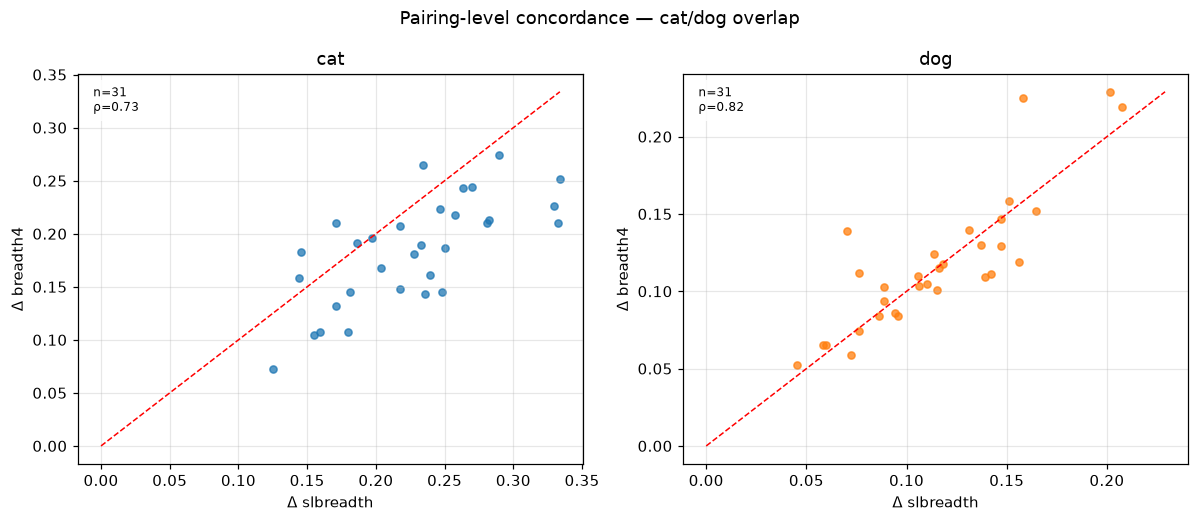

Schema drift (slbreadth vs breadth4, computed):
  slbreadth prompt sets: ['consensus', 'dislike', 'favorite', 'register', 'test', 'validation'] has storytelling: False
  slbreadth skipped_incomplete_seeds key: False
  slbreadth optimizer_resolved: False
  slbreadth probe block in manifest: False
  slbreadth triad at frozen tag: pref 94 fc 50 cap 50
  slbreadth benchmarks key: False
  breadth4 has storytelling, skipped_incomplete_seeds, optimizer_resolved, probe, benchmarks on headline, triad 188/188.


In [23]:
print("slbreadth tree:", SLBREADTH_TREE, "exists:", SLBREADTH_TREE.is_dir())
if not SLBREADTH_TREE.is_dir():
    print("slbreadth Stage B tree missing — skip concordance.")
else:
    sl_pref_all = load_gkd_preference_results(OUTPUT_ROOT, SLBREADTH_SUBDIR)
    sl_tags = sorted(sl_pref_all["gkd_tag"].dropna().unique())
    print("slbreadth gkd_tags:", sl_tags)
    sl_pref = sl_pref_all[sl_pref_all["gkd_tag"] == FROZEN].copy()
    if sl_pref.empty:
        print(f"No rows at frozen tag {FROZEN!r} in slbreadth — skip.")
    else:
        sl_delta = pairing_delta_frame(subliminal_delta(sl_pref), PRIMARY_SET)
        overlap_animals = [a for a in ANIMALS if a in set(sl_delta["animal"])]
        both = sl_delta.merge(
            pd_delta,
            on=["animal", "pairing"],
            suffixes=("_slbreadth", "_breadth4"),
            how="inner",
        )
        print_scope(both, "cat/dog pairing overlap vs slbreadth")
        print(f"overlap animals: {overlap_animals}  n_rows={len(both)}")
        for animal in overlap_animals:
            sub = both[both["animal"] == animal]
            rho, pval = spearmanr(sub["subliminal_delta_slbreadth"], sub["subliminal_delta_breadth4"])
            print(f"  {animal}: Spearman ρ={rho:.2f} p={pval:.3g} n={len(sub)}")
        fig, axes = plt.subplots(1, max(len(overlap_animals), 1), figsize=(5.5 * max(len(overlap_animals), 1), 4.8))
        axes = np.atleast_1d(axes)
        for ax, animal in zip(axes, overlap_animals):
            sub = both[both["animal"] == animal]
            aplots.identity_scatter(
                ax,
                sub,
                "subliminal_delta_slbreadth",
                "subliminal_delta_breadth4",
                stat="spearman",
                diag_lim=(0.0, max(0.05, float(sub.filter(like="subliminal_delta").max().max()))),
                color=ANIMAL_COLORS.get(animal, "C0"),
                s=22,
                alpha=0.75,
                title_stats=True,
                textbox=True,
            )
            ax.set_title(animal)
            ax.set_xlabel("Δ slbreadth")
            ax.set_ylabel("Δ breadth4")
        plt.suptitle("Pairing-level concordance — cat/dog overlap")
        plt.tight_layout()
        plt.show()

        # Schema drift vs this campaign (compute, do not paste).
        sl_treat_dirs = [
            p.parent
            for p in SLBREADTH_TREE.glob(f"*/*/*/{FROZEN}/preference_summary.json")
            if p.relative_to(SLBREADTH_TREE).parts[0] != "controls"
        ]
        sl_sample = json.loads(sl_treat_dirs[0].joinpath("preference_summary.json").read_text())
        sl_sets = sorted({s.get("prompt_set") for s in sl_sample.get("summaries", [])})
        sl_man = sl_treat_dirs[0] / "gseed0" / "train_manifest.json"
        sl_man_doc = json.loads(sl_man.read_text()) if sl_man.is_file() else {}
        sl_cap_path = sl_treat_dirs[0] / "sdf_capability_summary.json"
        sl_fc_n = sum(
            1 for d in sl_treat_dirs if (d / "sdf_forced_choice_summary.json").is_file()
        )
        sl_cap_n = sum(
            1 for d in sl_treat_dirs if (d / "sdf_capability_summary.json").is_file()
        )
        sl_cap_doc = json.loads(sl_cap_path.read_text()) if sl_cap_path.is_file() else {}
        print("Schema drift (slbreadth vs breadth4, computed):")
        print("  slbreadth prompt sets:", sl_sets, "has storytelling:", "storytelling" in sl_sets)
        print("  slbreadth skipped_incomplete_seeds key:", "skipped_incomplete_seeds" in sl_sample)
        print("  slbreadth optimizer_resolved:", "optimizer_resolved" in sl_man_doc)
        print("  slbreadth probe block in manifest:", "probe" in sl_man_doc)
        print(
            f"  slbreadth triad at frozen tag: pref {len(sl_treat_dirs)} "
            f"fc {sl_fc_n} cap {sl_cap_n}"
        )
        print("  slbreadth benchmarks key:", "benchmarks" in sl_cap_doc)
        print(
            "  breadth4 has storytelling, skipped_incomplete_seeds, "
            "optimizer_resolved, probe, benchmarks on headline, triad 188/188."
        )


## 19. Takeaways

**What this measures.** Numbers recomputed from frames as f-strings.
Then claims we can make / cannot make / scope limits, and how to extend
via the knobs.


In [24]:
def _fmt(x: float, nd: int = 3) -> str:
    return f"{x:.{nd}f}" if x == x else "nan"


takeaways = [
    f"Frozen tag {FROZEN} is the unique Stage B gkd_tag; "
    f"{len(treat_dirs)} treat configs / {len(treat_leaves)} leaves, "
    f"{len(ctrl_dirs)} control configs / {len(ctrl_leaves)} leaves.",
    f"Eval triad is {pref_t}/{pref_t} treat and {pref_c}/{pref_c} control "
    f"(100%), vs slbreadth's incomplete FC+capability triad.",
    f"Stage A overlap is {len(overlap_treat)} treat + {len(overlap_ctrl)} "
    f"control dirs (A3 ref spine at the freeze winner).",
    "init_equality verdict is as_expected — the premise for shared-init vs "
    "shared-stream labels.",
]
for row in cloud_h.itertuples():
    takeaways.append(
        f"Cloud test {row.animal} headline: same-init mean={_fmt(row.same_mean)} "
        f"cross-init mean={_fmt(row.cross_mean)} "
        f"cross_positive_frac={_fmt(row.cross_positive_frac, 2)} "
        f"sign-test p={_fmt(row.cross_sign_p, 4)}."
    )
takeaways.append(
    f"Animal heterogeneity: Kruskal-Wallis H={kw.statistic:.2f} p={kw.pvalue:.3g}; "
    f"Friedman Q={fried.statistic:.2f} p={fried.pvalue:.3g}; "
    f"VC animal share={vc.fractions['animal']:.3f}."
)
takeaways.append(
    f"n=4 teacher-vs-freeze-Δ Spearman ρ={rho4:.2f} p={p4:.3g} (underpowered). "
    f"n=28 (animal, init) Spearman ρ={rho28:.2f} p={p28:.3g}. "
    f"Transfer efficiency (freeze Δ / mean teacher): "
    + ", ".join(f"{a}={eff4[a]:.2f}" for a in ANIMALS)
    + "."
)
takeaways.append(
    "delta_vs_same_init_anchor is a notebook-local construct (checkpoint-ladder y "
    "precedent), not a repo-standard metric."
)
if not st_vs_test.empty:
    for animal in ANIMALS:
        sub = st_vs_test[st_vs_test["animal"] == animal]
        if len(sub) >= 3:
            rho, pval = spearmanr(sub["test"], sub["storytelling"])
            takeaways.append(
                f"Storytelling vs test {animal}: Spearman ρ={rho:.2f} p={pval:.3g} n={len(sub)}."
            )
takeaways.append(
    f"lm-eval coverage: headline {n_head_bench}/{n_head}, extension {n_ext_bench}/{n_ext} "
    f"(absent by design), controls {n_ctrl_bench}/{len(cap_ctrl)}."
)
takeaways.append(
    f"Probe dedup: {n_dup_leaves} leaves had duplicate steps; "
    f"diverged treat leaves={len(div_leaves)}; step 0 present."
)

print("TAKEAWAYS (recomputed from frames):")
for i, line in enumerate(takeaways, 1):
    print(f"{i:2d}. {line}")

print("\n--- Claims we can make ---")
print(
    "- On-policy GKD at the frozen recipe produces a positive Cloud SL Δ "
    "against matched base-teacher controls on the designed Stage B grid "
    "(L0), with the triad complete on every frozen config."
)
print(
    "- The same recipe was run on four animals (L1); animal is a measured "
    "factor (VC / KW / Friedman), not a licence to pool raw p_target."
)
print(
    "- Cloud's shared-initialization requirement is tested by "
    "cross_positive_frac and same-vs-cross means at four animals (L2). "
    "Read those printed values; do not import a verdict from the 2-animal notebook."
)
print(
    "- Storytelling (sample, OOD) is present on every treat config and can "
    "be compared to test (L4) via the printed pairing Spearman."
)
print(
    "- Teacher-strength and student-base confounds are measured; n=4 "
    "teacher–Δ Spearman is underpowered."
)

print("\n--- Claims we cannot make ---")
print(
    "- No H1/H2 verdict (batch-composition vs weight-init as the carrier). "
    "The campaign plan excludes re-litigating that pair; the earlier run "
    "left H1 inconclusive with a wrong-signed point estimate."
)
print("- No causal claim that teacher strength *is* animal heterogeneity.")
print("- No claim that extension (1×3) has the same precision as headline (3×3).")
print("- No claim from probe p_target as if it were eval-grade preference.")
print("- No lm-eval claim on extension dirs (key absent by design).")
print("- Pairing rankings are post-hoc (no Stage-B pre-registration).")

print("\n--- Scope limits ---")
print(
    "Out of scope: β=0 / forward KL, Stage C (λ / vocab_mask / full-FT teacher), "
    "CKA / EAS / steering, random-teacher / shuffle / ICL negatives, "
    "PolyPythia seeds 1–9, model-size sweeps, promoting extension arms to 3 tfs."
)


TAKEAWAYS (recomputed from frames):
 1. Frozen tag lmb1.0_b1.0_lora_lr4e-4_e1_r8a16 is the unique Stage B gkd_tag; 188 treat configs / 564 leaves, 28 control configs / 84 leaves.
 2. Eval triad is 188/188 treat and 28/28 control (100%), vs slbreadth's incomplete FC+capability triad.
 3. Stage A overlap is 8 treat + 4 control dirs (A3 ref spine at the freeze winner).
 4. init_equality verdict is as_expected — the premise for shared-init vs shared-stream labels.
 5. Cloud test cat headline: same-init mean=0.220 cross-init mean=0.193 cross_positive_frac=1.00 sign-test p=0.0156.
 6. Cloud test dog headline: same-init mean=0.137 cross-init mean=0.125 cross_positive_frac=1.00 sign-test p=0.0156.
 7. Cloud test bear headline: same-init mean=0.409 cross-init mean=0.320 cross_positive_frac=1.00 sign-test p=0.0156.
 8. Cloud test eagle headline: same-init mean=0.271 cross-init mean=0.147 cross_positive_frac=1.00 sign-test p=0.0156.
 9. Animal heterogeneity: Kruskal-Wallis H=48.30 p=1.84e-10; Fri

### How to extend

Knobs in the setup cell:

| Knob | Role |
|---|---|
| `ANIMALS` | Imported from `breadth_plan`; slice to a subset to re-run plots. |
| `PROMPT_SETS` | Defaults to `EVAL_PROMPT_SETS` (includes storytelling). |
| `PRIMARY_SET` | Endpoint for Δ / Cloud / corners (`test`). |
| `BOOTSTRAP_SEED` / `N_BOOT` | Pairing-cluster bootstrap (`astats` defaults). |
| `DEEP_ANIMAL` | Which animal gets the raw `p_target` companion heatmap. |

Re-run from the load cell downward after changing a knob. Do not write
under `output_root`. Do not pool headline with extension. Do not treat
`delta_vs_same_init_anchor` as a pipeline metric. Do not fill empty 7×7
cells with 0 and call them observed Δ.
